In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('straingauge_raw.csv')
df['date_time_dimension_full_date'] = pd.to_datetime(df['date_time_dimension_full_date'])

# Filtrar
df = df[df['date_time_dimension_full_date'].dt.year >= 2008]
df

,date_time_dimension_full_date,sensor_strain_gauge_raw_engineer_vw,sensor_strain_gauge_rawfksensor_id
19290,2008-01-04 00:00:00,4949.30,23
19291,2008-01-04 00:00:00,6243.50,19
19292,2008-01-04 00:00:00,6395.50,20
19293,2008-01-04 00:00:00,5646.00,22
19294,2008-01-04 00:00:00,5819.10,21
...,...,...,...
30900,2020-08-04 15:00:00,4824.08,7
30901,2020-08-04 15:00:00,5222.57,11
30902,2020-08-04 15:00:00,5336.23,10
30903,2020-08-04 15:00:00,4583.09,12


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11615 entries, 19290 to 30904
Data columns (total 3 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   date_time_dimension_full_date        11615 non-null  datetime64[ns]
 1   sensor_strain_gauge_raw_engineer_vw  11143 non-null  float64       
 2   sensor_strain_gauge_rawfksensor_id   11615 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(1)
memory usage: 363.0 KB


In [ ]:
df = df.dropna()

###Análise crua

Text(0.5, 1.0, 'Quantidade de registros por Sensor')

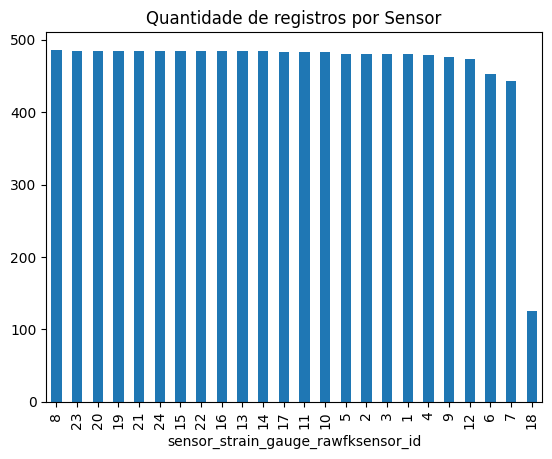

In [ ]:
df['sensor_strain_gauge_rawfksensor_id'].value_counts().plot(kind='bar')
plt.title("Quantidade de registros por Sensor")

In [ ]:
# Contagem exata de registros
contagem_sensores = df['sensor_strain_gauge_rawfksensor_id'].value_counts().sort_index()
df_contagem = contagem_sensores.to_frame(name='quantidade_registros')
df_contagem.index.name = 'sensor_id'

# Calcular quanto falta em relação ao sensor que tem mais dados
max_registros = df_contagem['quantidade_registros'].max()
df_contagem['diferenca_para_o_max'] = max_registros - df_contagem['quantidade_registros']

print(df_contagem)

           quantidade_registros  diferenca_para_o_max
sensor_id                                            
1                           480                     6
2                           480                     6
3                           480                     6
4                           479                     7
5                           480                     6
6                           452                    34
7                           443                    43
8                           486                     0
9                           476                    10
10                          483                     3
11                          483                     3
12                          473                    13
13                          484                     2
14                          484                     2
15                          484                     2
16                          484                     2
17                          

In [ ]:
duplicados = df.groupby(['date_time_dimension_full_date', 'sensor_strain_gauge_rawfksensor_id']).size()
print(f"Número de duplicatas: {len(duplicados[duplicados > 1])}")

Número de duplicatas: 0


In [ ]:
df['sensor_strain_gauge_raw_engineer_vw'].describe()


,sensor_strain_gauge_raw_engineer_vw
count,11143.000000
mean,5131.923019
std,631.371827
min,3825.200000
25%,4616.950000
50%,5193.500000
75%,5502.125000
max,8441.070000


In [ ]:
inconsistentes = df[df['sensor_strain_gauge_raw_engineer_vw'] <= 0]
print(f"Linhas com valores <= 0: {len(inconsistentes)}")

Linhas com valores <= 0: 0


In [ ]:
def count_outliers(group):
    Q1 = group.quantile(0.25)
    Q3 = group.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return ((group < lower) | (group > upper)).sum()

# Agrupa por sensor e conta os outliers de cada um
outliers_por_sensor = df.groupby('sensor_strain_gauge_rawfksensor_id')['sensor_strain_gauge_raw_engineer_vw'].apply(count_outliers)

print("Outliers por Sensor:")
print(outliers_por_sensor[outliers_por_sensor > 0])
print(f"\nTotal de outliers: {outliers_por_sensor.sum()}")

Outliers por Sensor:
sensor_strain_gauge_rawfksensor_id
1      1
3      1
4      2
5      1
7      3
9      8
10     4
12    57
13     1
14     3
16     5
17     4
18     2
19     1
20     3
22    81
23     1
24    10
Name: sensor_strain_gauge_raw_engineer_vw, dtype: int64

Total de outliers: 188


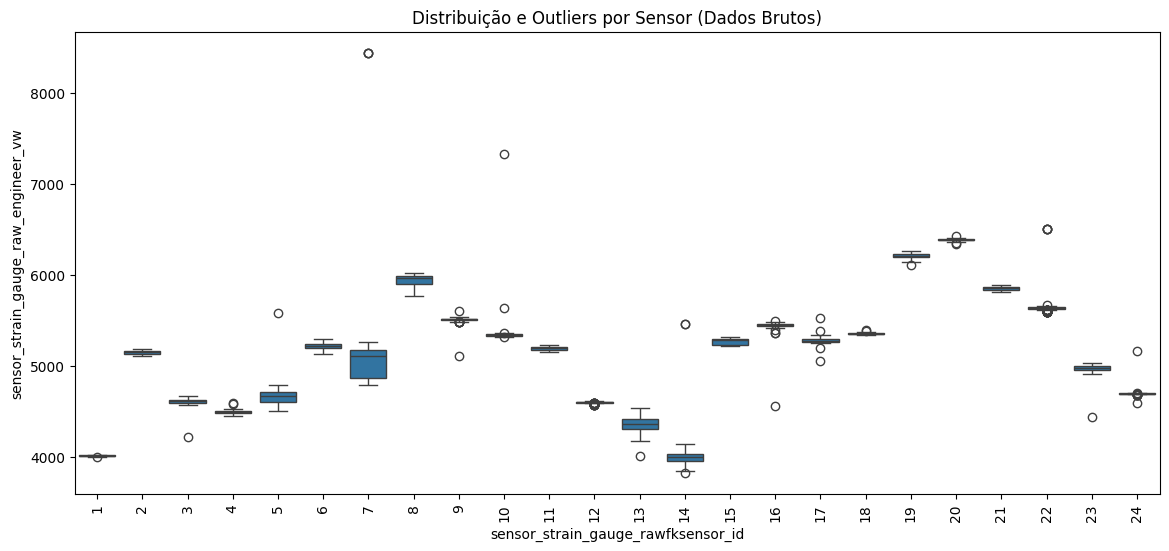

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
sns.boxplot(x='sensor_strain_gauge_rawfksensor_id',
            y='sensor_strain_gauge_raw_engineer_vw',
            data=df)
plt.title("Distribuição e Outliers por Sensor (Dados Brutos)")
plt.xticks(rotation=90)
plt.show()

##Reorganização do dataset

In [ ]:
#Pivotar pra mostrar sinal em tempo
df_pivot = df.pivot_table(index='date_time_dimension_full_date',
                          columns='sensor_strain_gauge_rawfksensor_id',
                          values='sensor_strain_gauge_raw_engineer_vw')


In [ ]:
df_pivot

sensor_strain_gauge_rawfksensor_id,1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,23,24
date_time_dimension_full_date,,,,,,,,,,,,,,,,,,,,,
2008-01-04 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,6243.50,6395.50,5819.10,5646.00,4949.30,4692.30
2008-01-04 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,5216.40,5433.60,5254.10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2008-01-04 09:00:00,NaN,NaN,NaN,NaN,NaN,NaN,5152.20,5982.40,5494.4,5341.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2008-01-04 12:00:00,4011.00,5123.2,4576.80,4462.20,4759.90,5246.90,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2008-01-10 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,6248.10,6398.50,5820.20,5647.20,4950.00,4693.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-07-03 14:00:00,NaN,NaN,NaN,NaN,NaN,NaN,4848.80,5868.41,NaN,5346.31,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-08-04 06:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,6171.07,6337.11,5865.23,5607.48,5028.19,4684.47
2020-08-04 07:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,5298.71,5461.44,5263.64,5360.97,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Puxar por dia
df_daily = df_pivot.resample('D').mean()

In [ ]:
df_daily

sensor_strain_gauge_rawfksensor_id,1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,23,24
date_time_dimension_full_date,,,,,,,,,,,,,,,,,,,,,
2008-01-04,4011.00,5123.2,4576.80,4462.20,4759.90,5246.90,5152.20,5982.40,5494.4,5341.00,...,5216.40,5433.60,5254.10,NaN,6243.50,6395.50,5819.10,5646.00,4949.30,4692.30
2008-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2008-01-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2008-01-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2008-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-07-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-08-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-08-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


sensor_strain_gauge_rawfksensor_id
1     4117
2     4117
3     4117
4     4118
5     4117
6     4145
7     4155
8     4113
9     4121
10    4114
11    4114
12    4124
13    4117
14    4117
15    4117
16    4117
17    4119
18    4472
19    4113
20    4113
21    4113
22    4113
23    4113
24    4113
dtype: int64


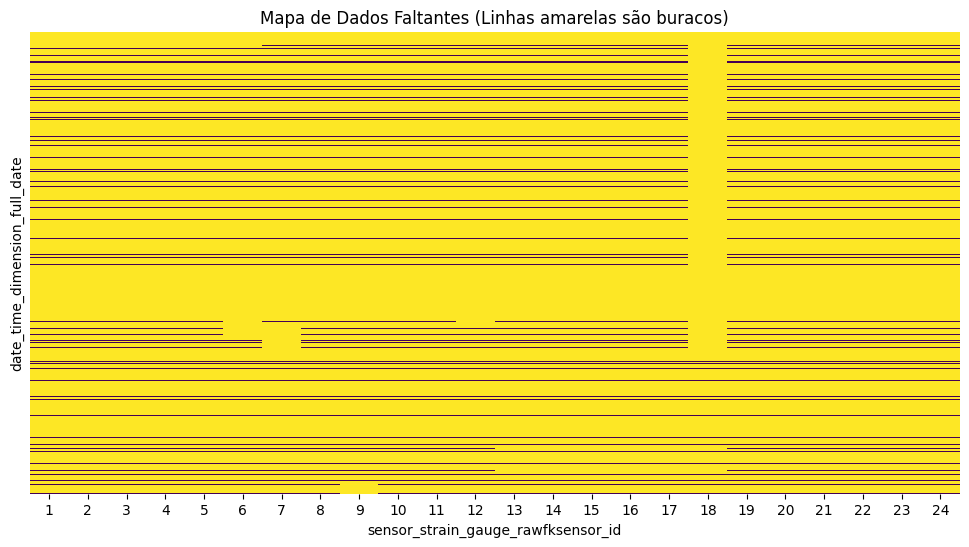

In [ ]:
# Null por dia
print(df_daily.isnull().sum())

# Visualizar onde estão os buracos
import seaborn as sns
plt.figure(figsize=(12, 6))
sns.heatmap(df_daily.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title("Mapa de Dados Faltantes (Linhas amarelas são buracos)")
plt.show()

##Testesemlimpeza

In [ ]:
df_sujo = df_daily.interpolate(method='linear').bfill().ffill()

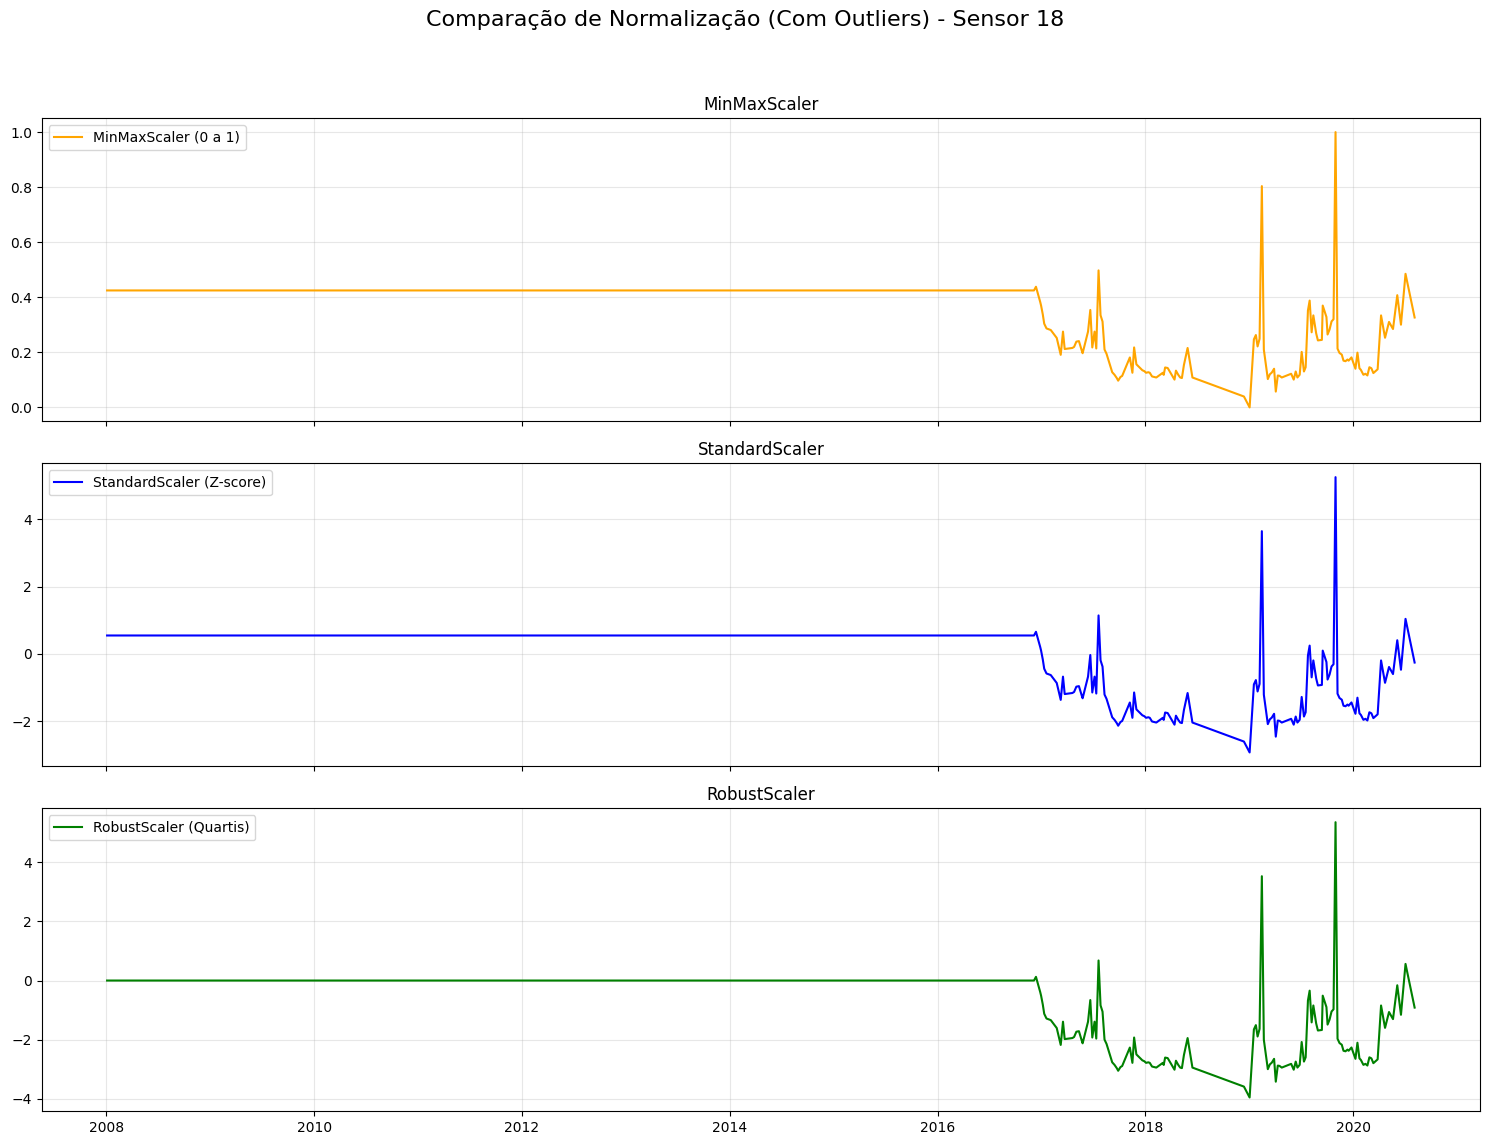

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
import matplotlib.pyplot as plt

def comparar_normalizacoes(df, sensor_id):
    data = df[[sensor_id]].values

    # 1. MinMaxScaler
    mms = MinMaxScaler()
    data_minmax = mms.fit_transform(data)

    # 2. StandardScaler
    ss = StandardScaler()
    data_std = ss.fit_transform(data)

    # 3. RobustScaler
    rs = RobustScaler()
    data_robust = rs.fit_transform(data)

    # Plotagem
    fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)
    fig.suptitle(f'Comparação de Normalização (Com Outliers) - Sensor {sensor_id}', fontsize=16)

    # Gráfico MinMax
    axes[0].plot(df.index, data_minmax, color='orange', label='MinMaxScaler (0 a 1)')
    axes[0].set_title("MinMaxScaler")
    axes[0].legend(loc='upper left')
    axes[0].grid(alpha=0.3)

    # Gráfico Standard
    axes[1].plot(df.index, data_std, color='blue', label='StandardScaler (Z-score)')
    axes[1].set_title("StandardScaler")
    axes[1].legend(loc='upper left')
    axes[1].grid(alpha=0.3)

    # Gráfico Robust
    axes[2].plot(df.index, data_robust, color='green', label='RobustScaler (Quartis)')
    axes[2].set_title("RobustScaler")
    axes[2].legend(loc='upper left')
    axes[2].grid(alpha=0.3)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Exemplo de uso para um sensor crítico
comparar_normalizacoes(df_sujo, 18)

##Limpezadataset

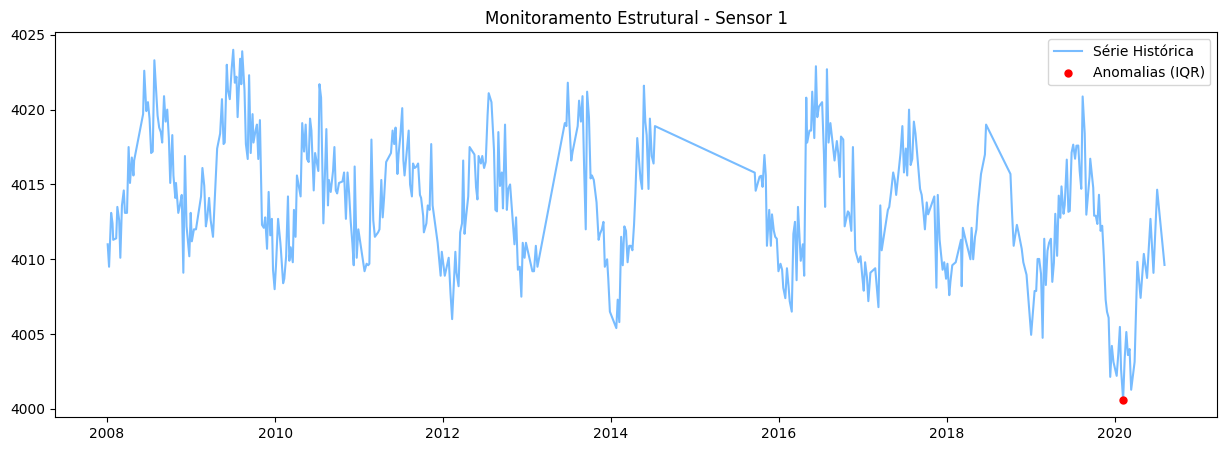

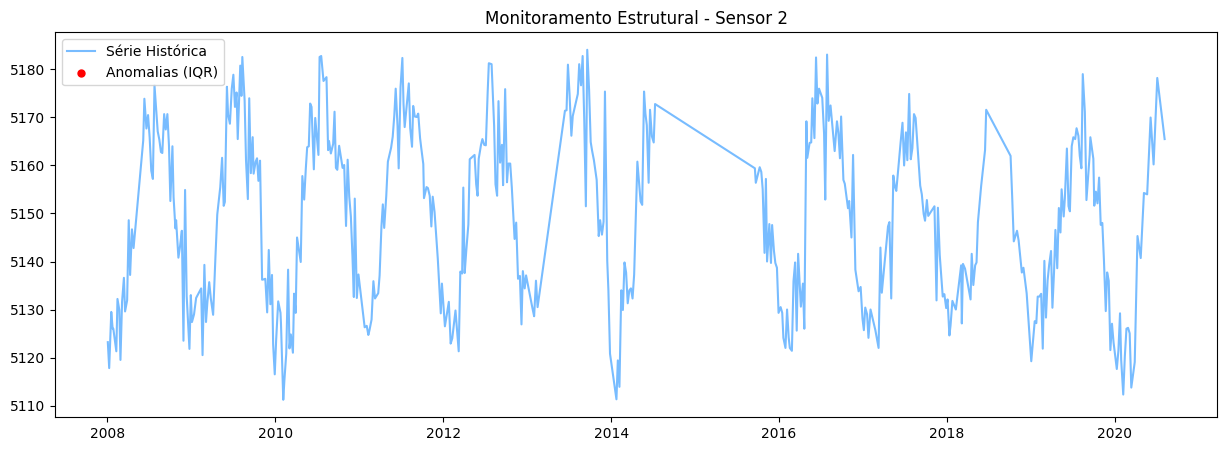

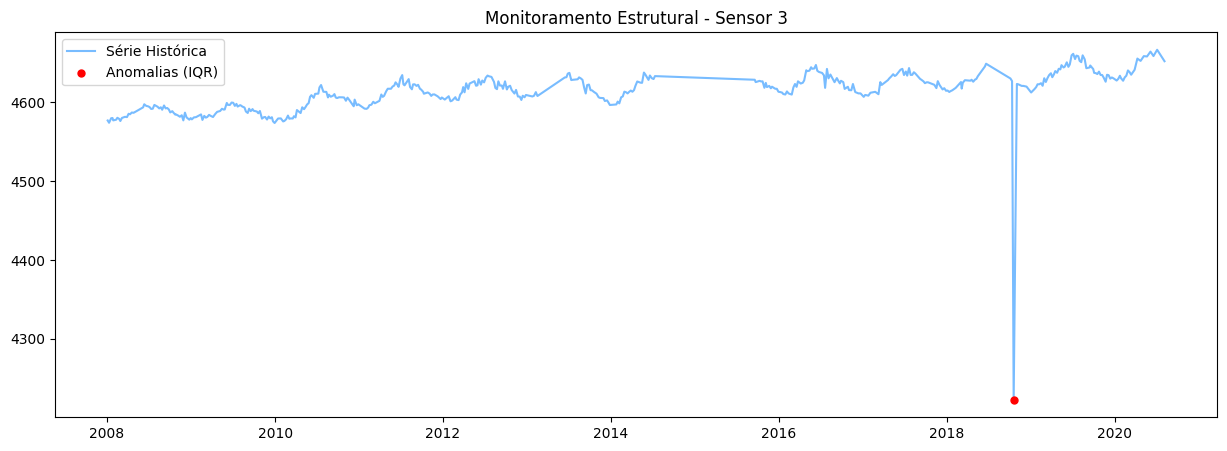

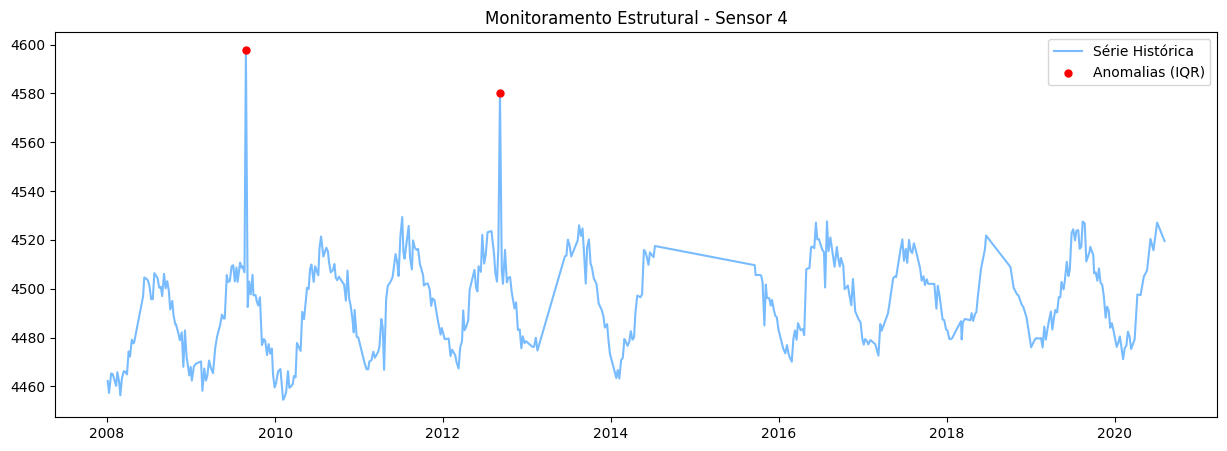

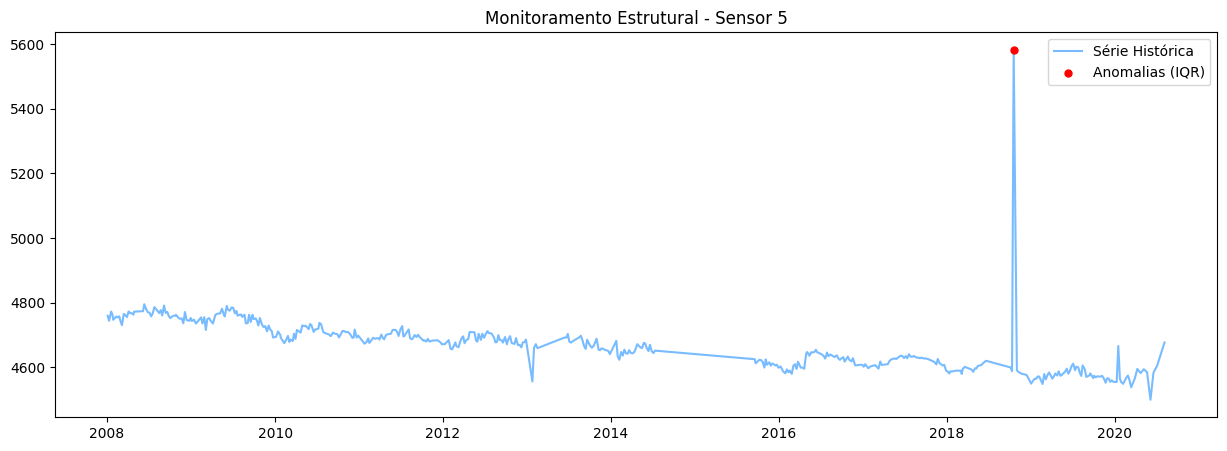

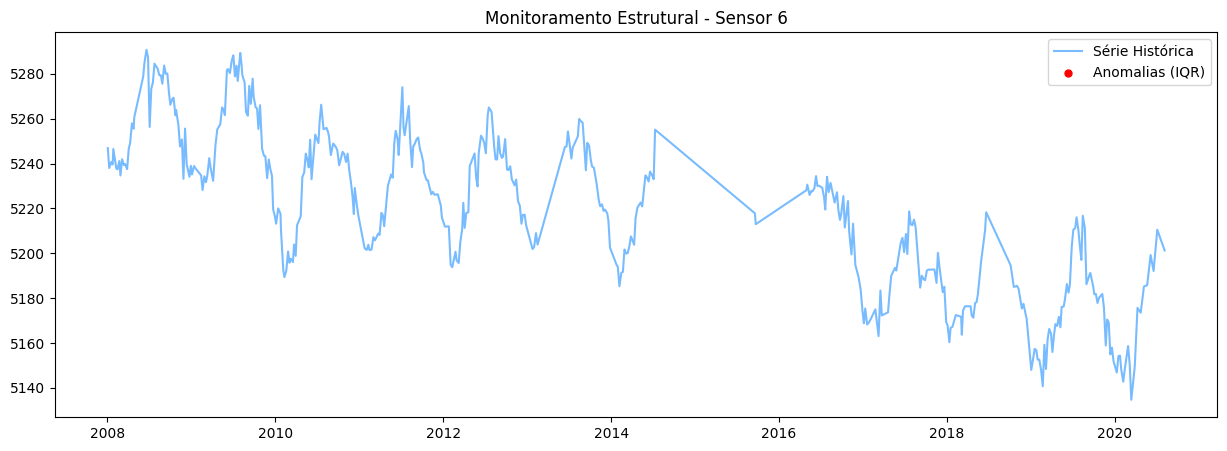

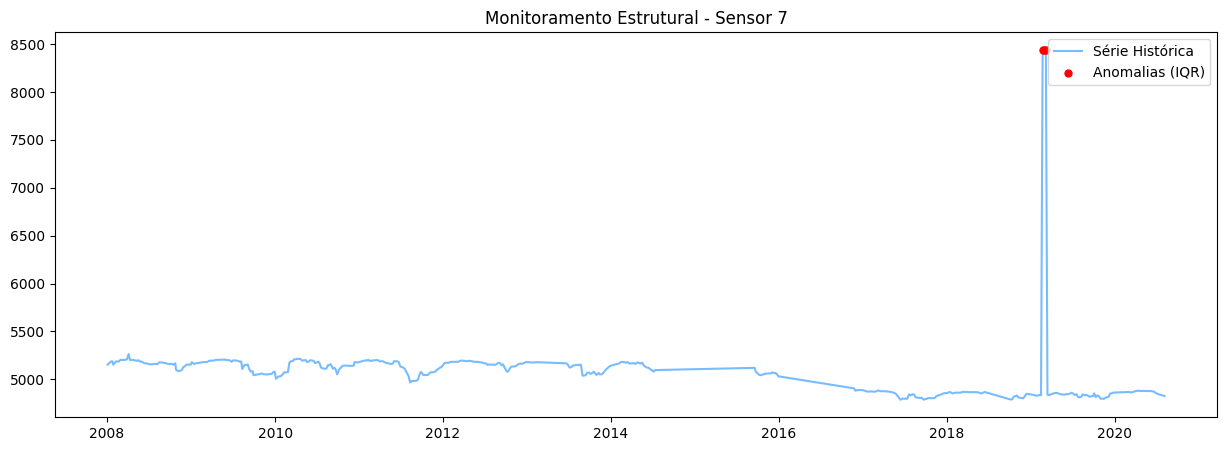

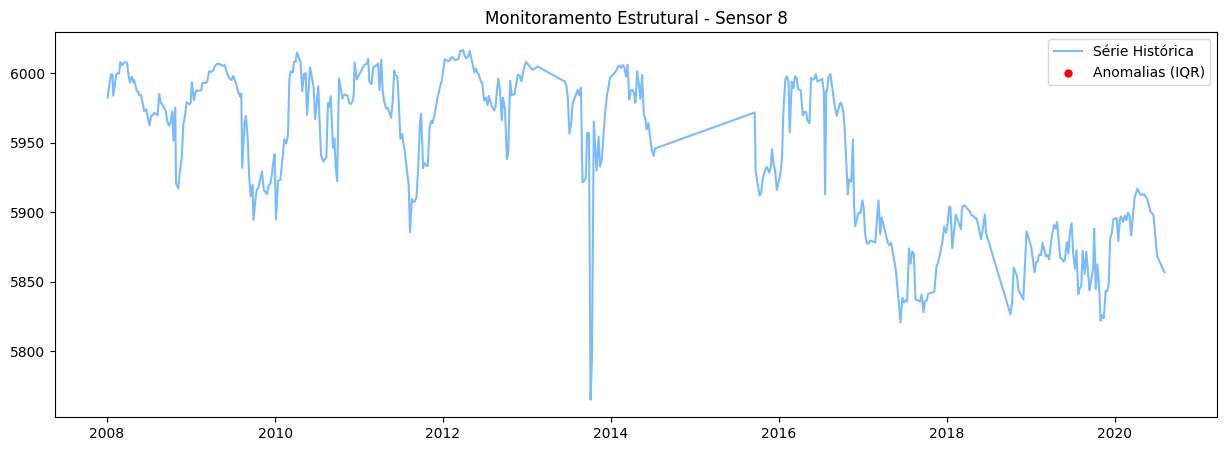

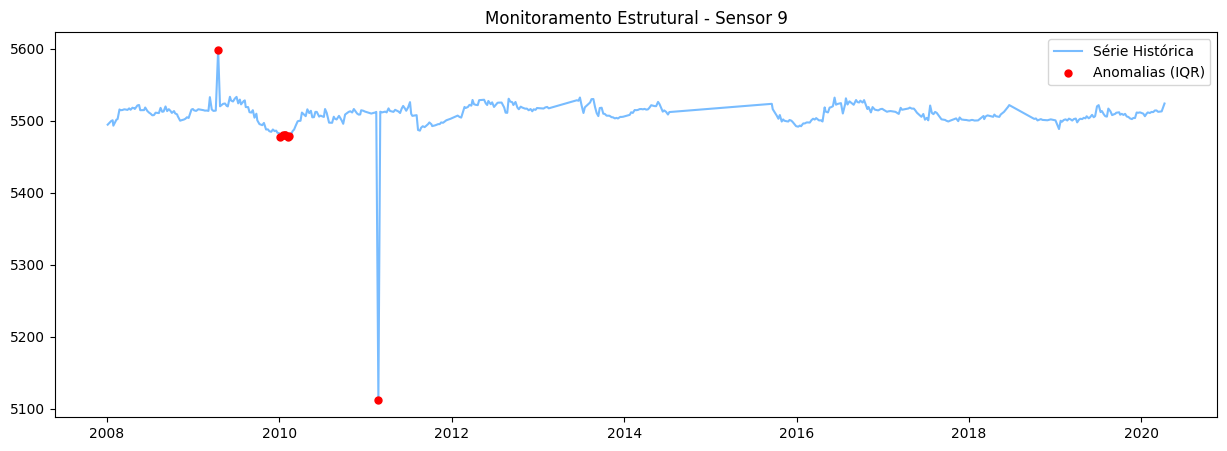

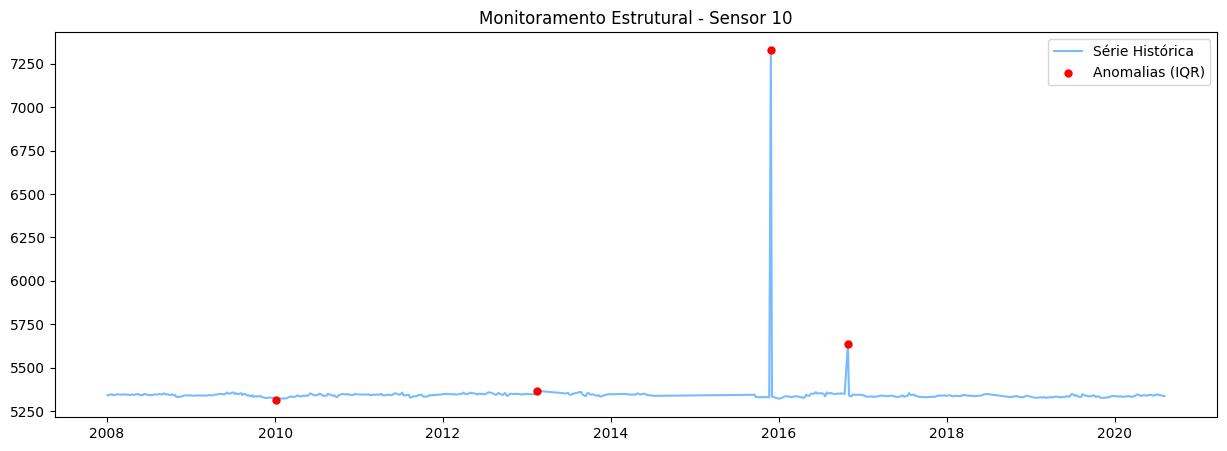

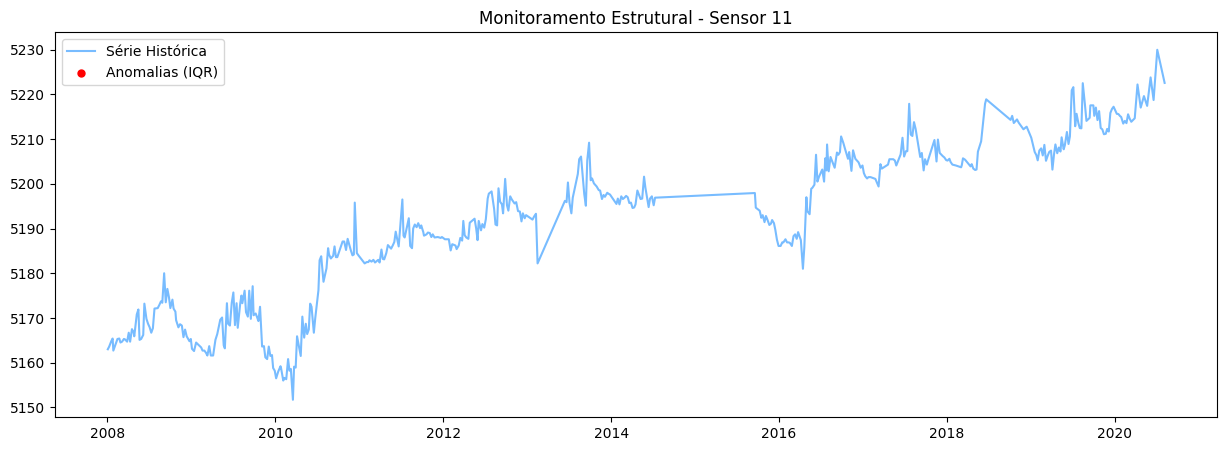

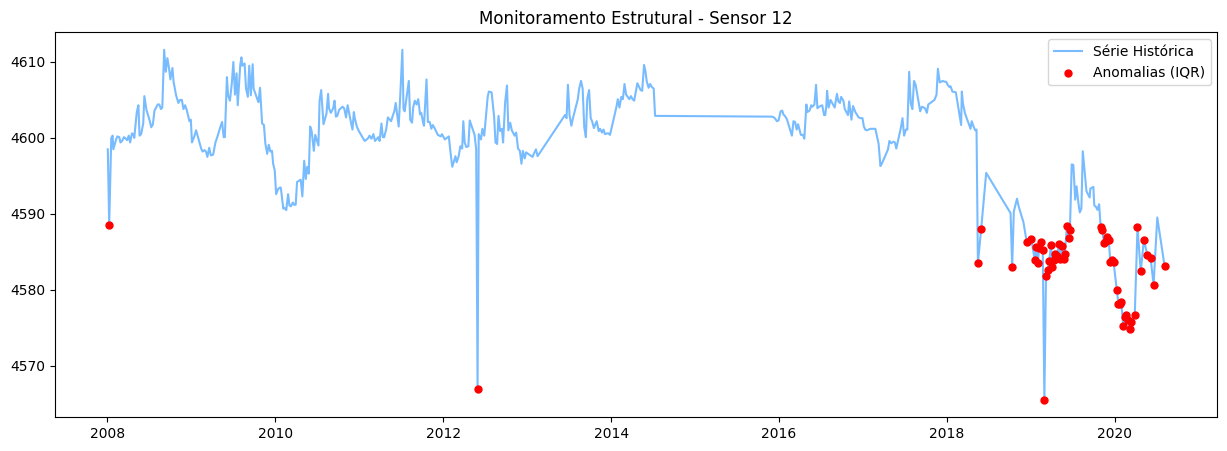

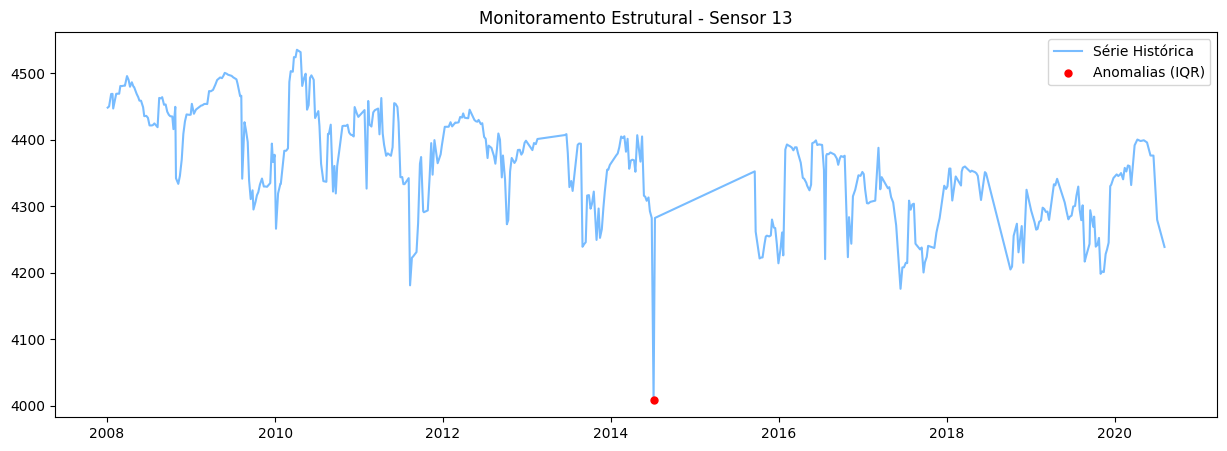

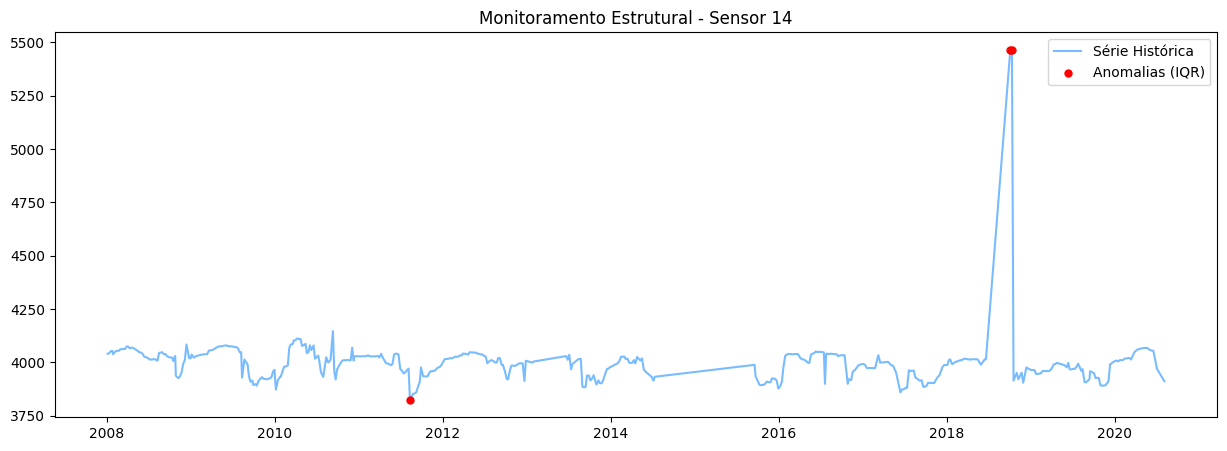

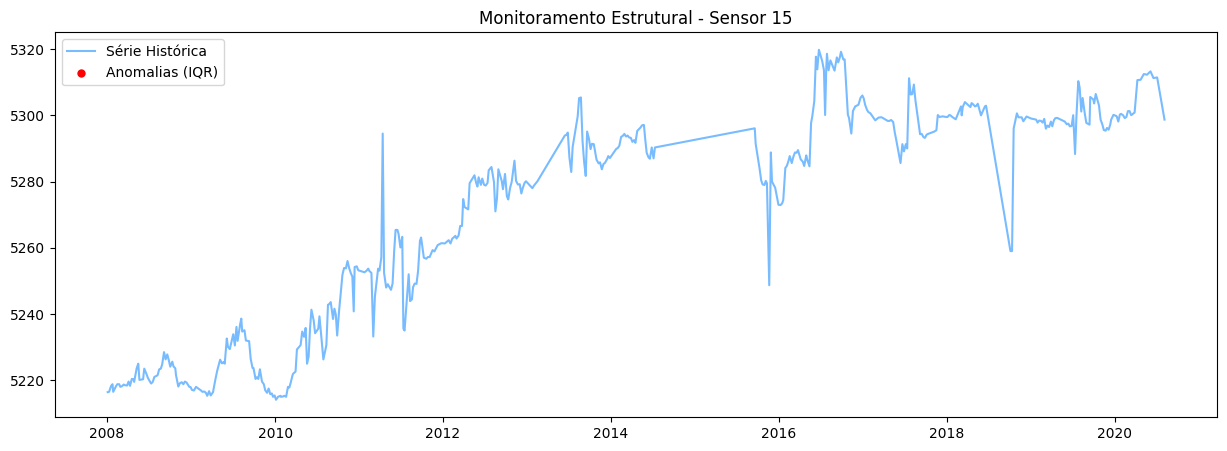

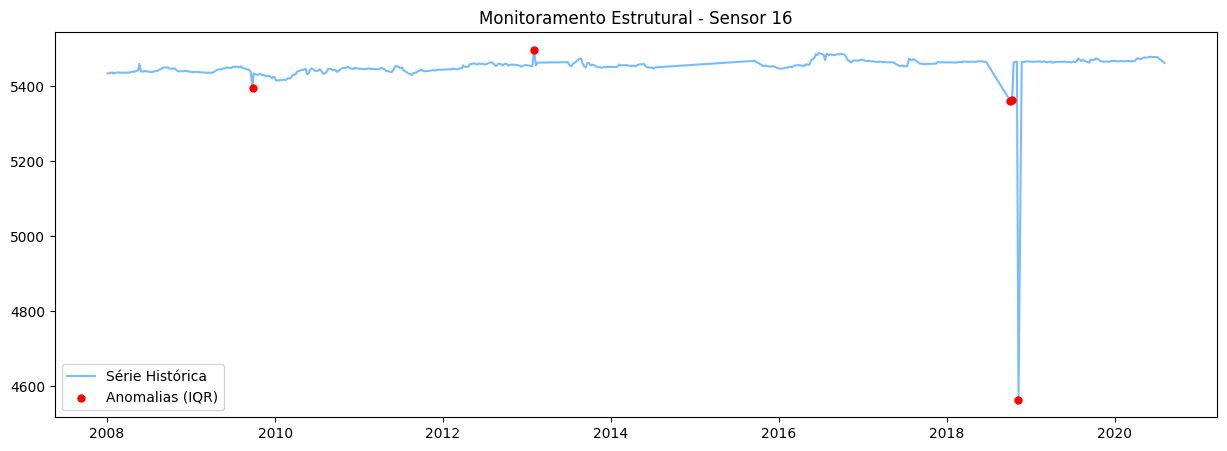

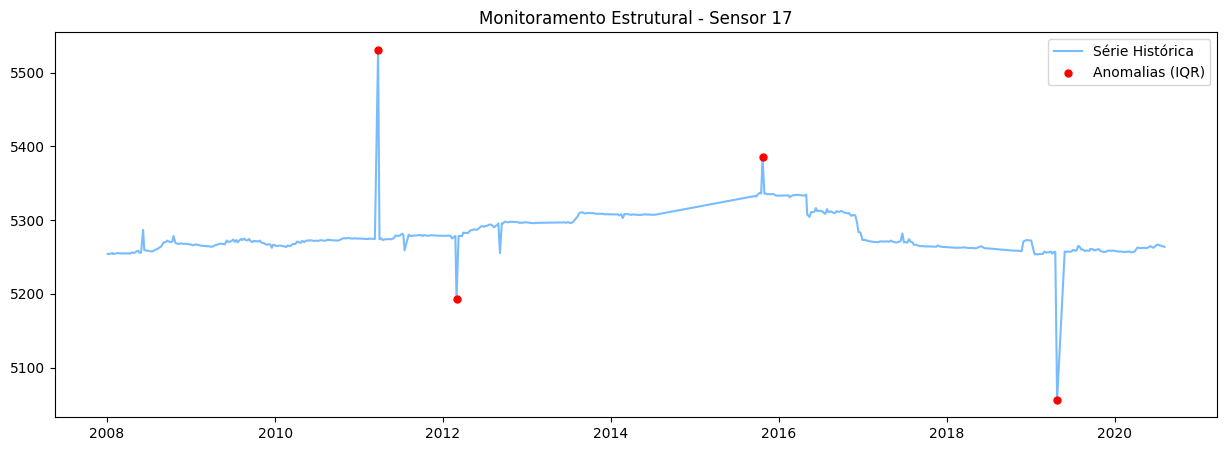

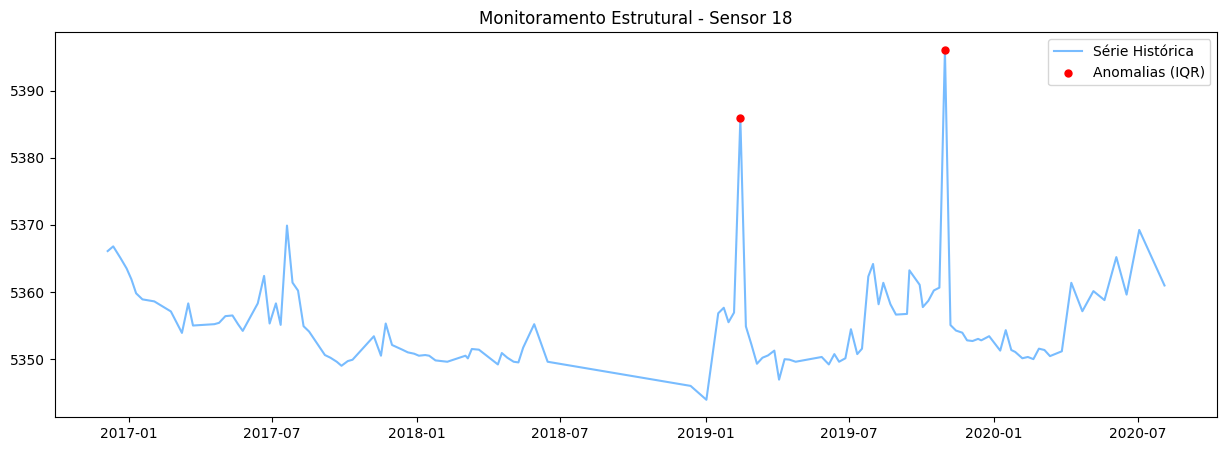

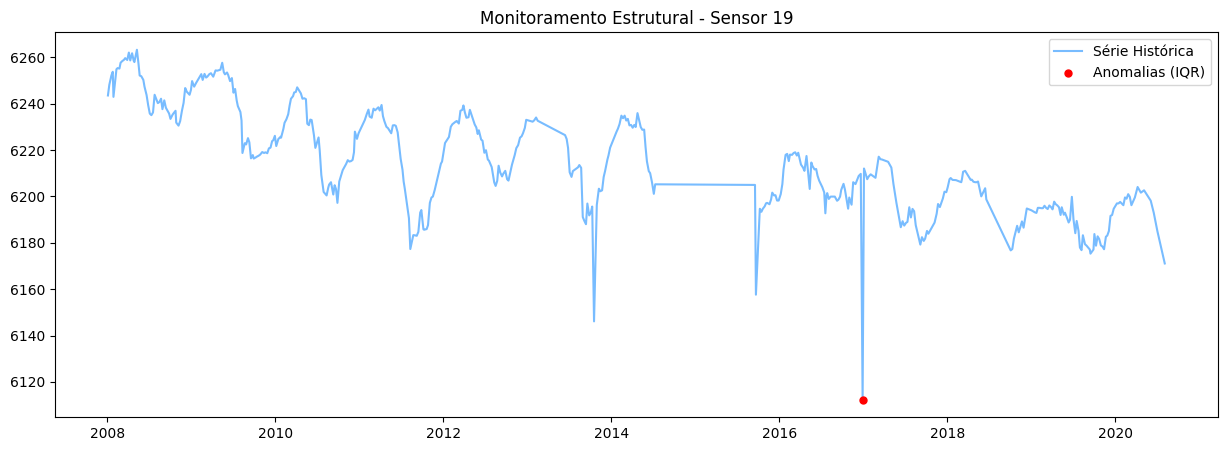

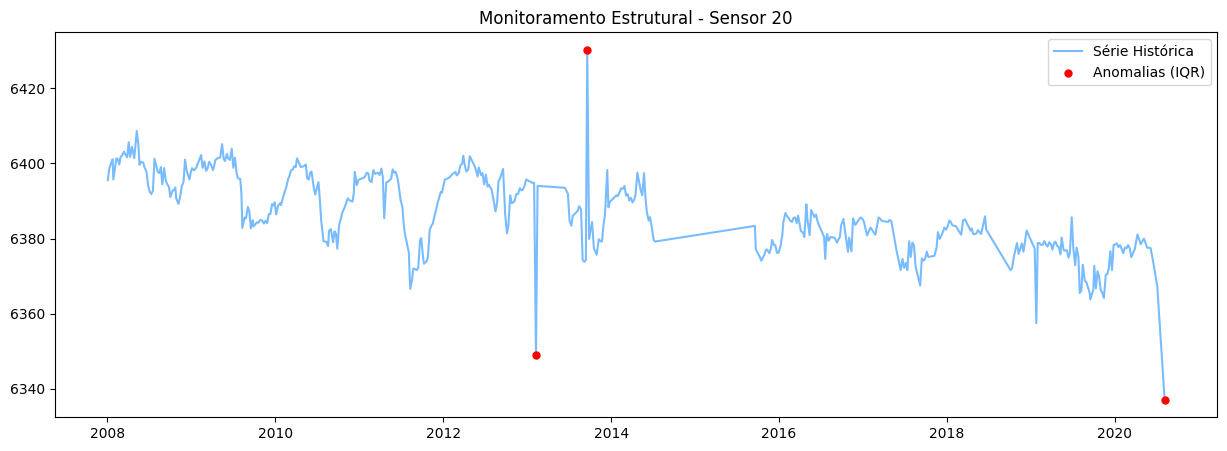

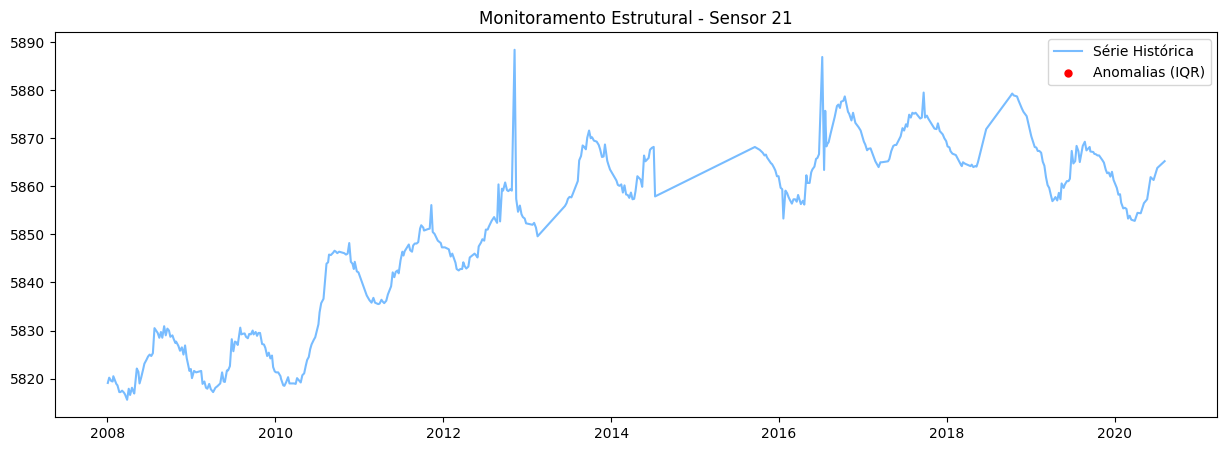

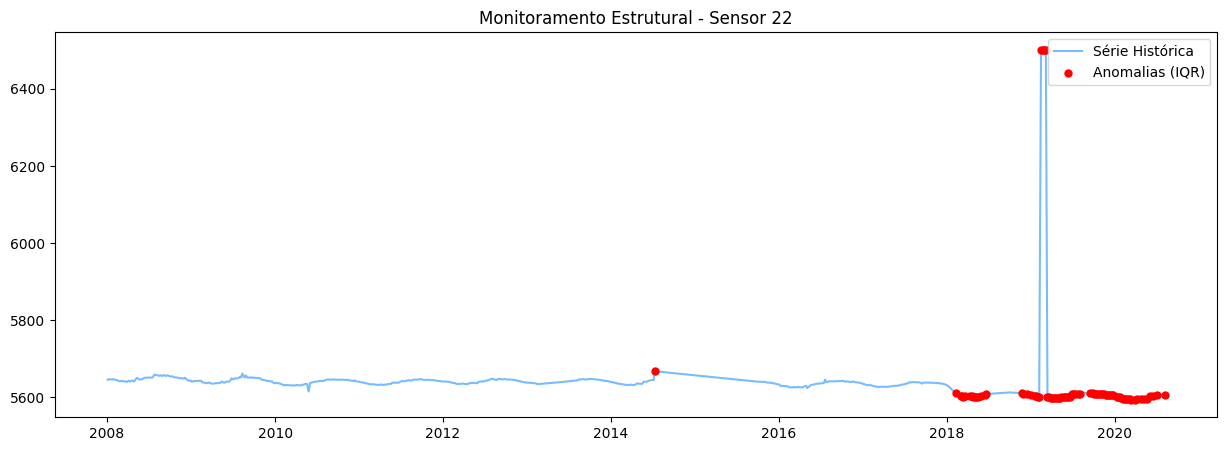

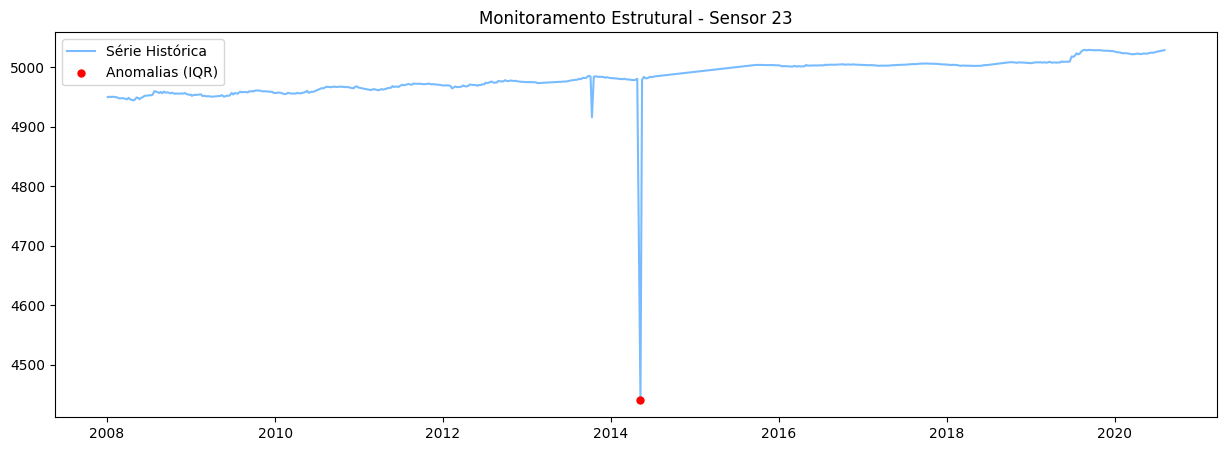

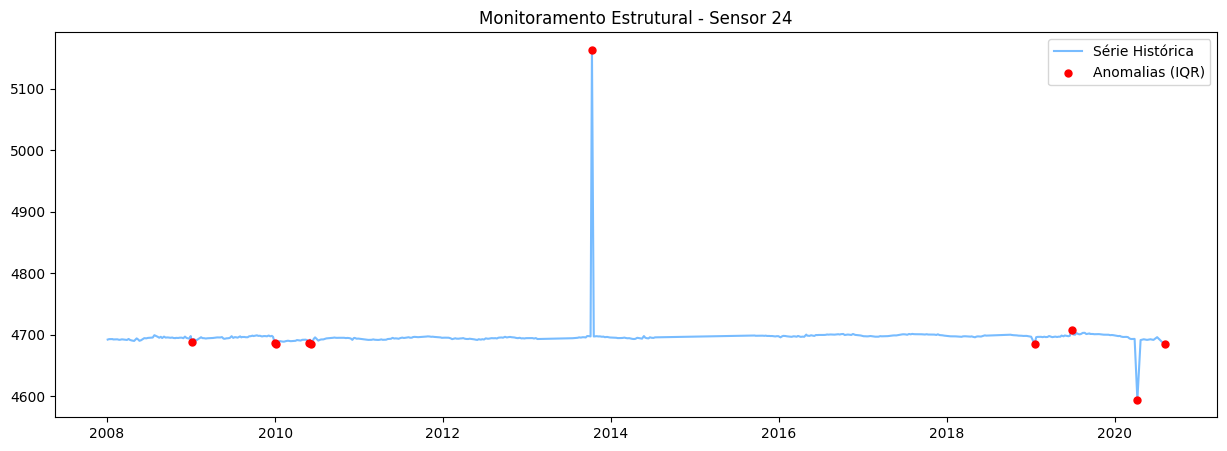

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_sensor_anomalies(df, sensor_id):
    df_plot = df[[sensor_id]].dropna()

    if df_plot.empty:
        print(f"Sensor {sensor_id} não possui dados para plotar.")
        return

    # 1. Cálculo do IQR (teste)
    Q1 = df[sensor_id].quantile(0.25)
    Q3 = df[sensor_id].quantile(0.75)
    IQR = Q3 - Q1
    upper = Q3 + 1.5 * IQR
    lower = Q1 - 1.5 * IQR

    # 2. Identificação de anomalias no df_plot
    anomalies = df_plot[(df_plot[sensor_id] > upper) | (df_plot[sensor_id] < lower)]

    plt.figure(figsize=(15, 5))

    # plotando o df (sem NaN)
    plt.plot(df_plot.index, df_plot[sensor_id], color='dodgerblue', label='Série Histórica', alpha=0.6)

    # Pontos de anomalia em vermelho
    plt.scatter(anomalies.index, anomalies[sensor_id], color='red', label='Anomalias (IQR)', s=25, zorder=3)

    plt.title(f"Monitoramento Estrutural - Sensor {sensor_id}")
    plt.legend()
    plt.show()

# plot
for col in df_daily.columns:
    plot_sensor_anomalies(df_daily, col)

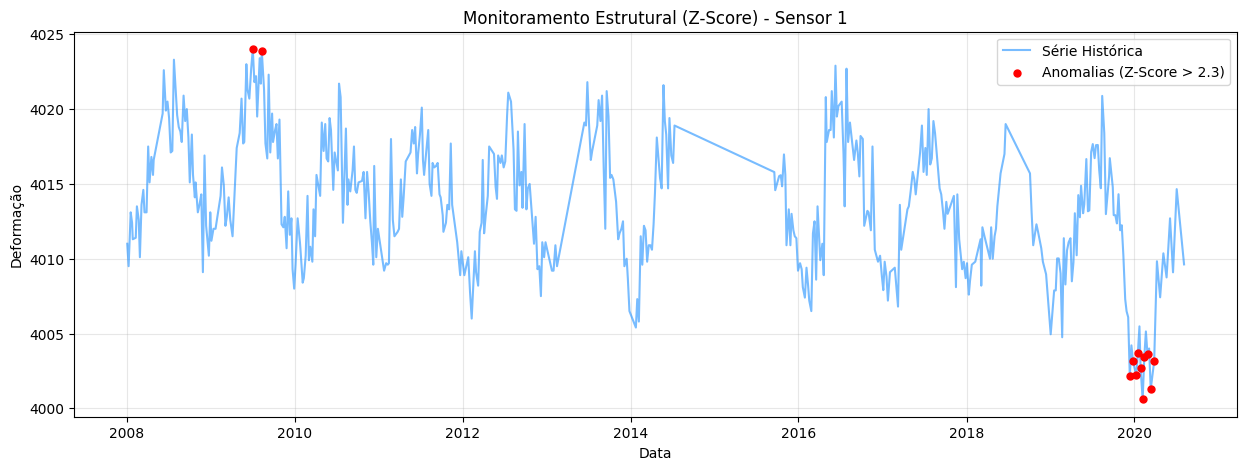

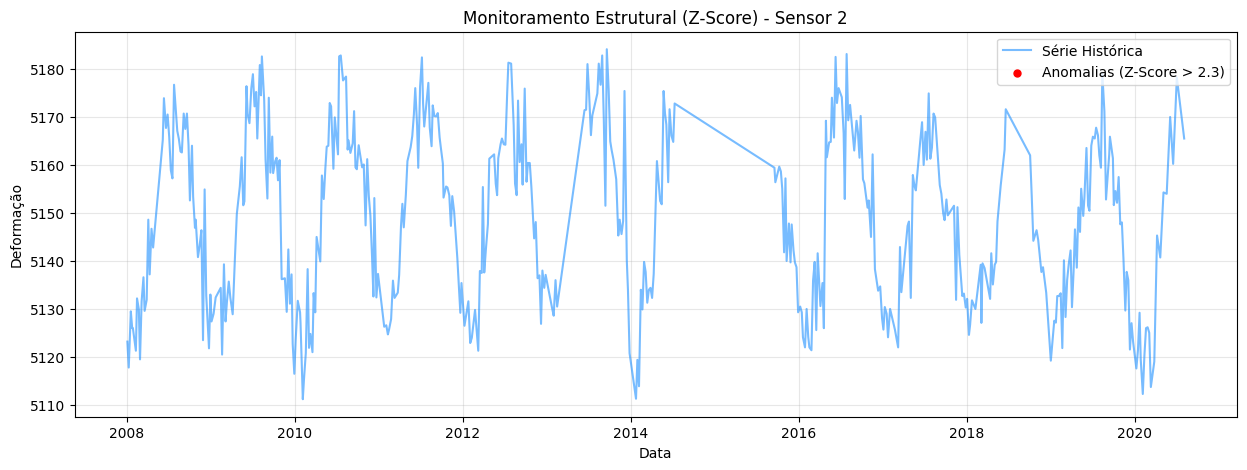

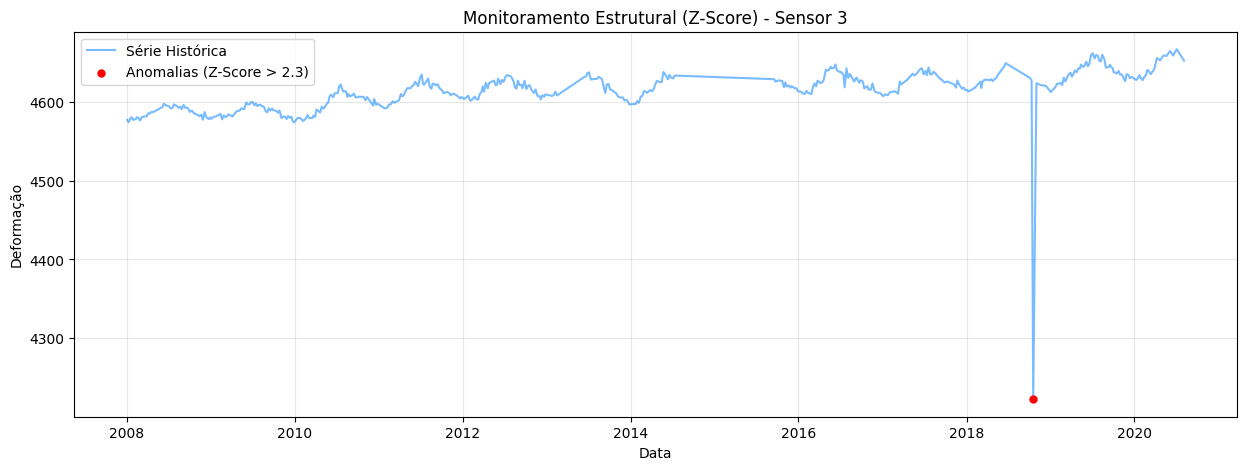

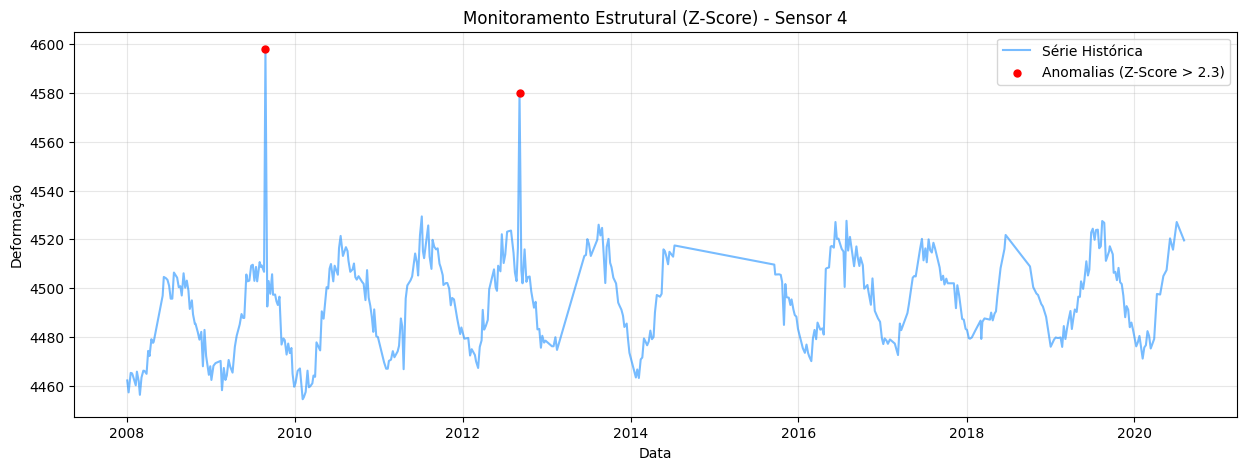

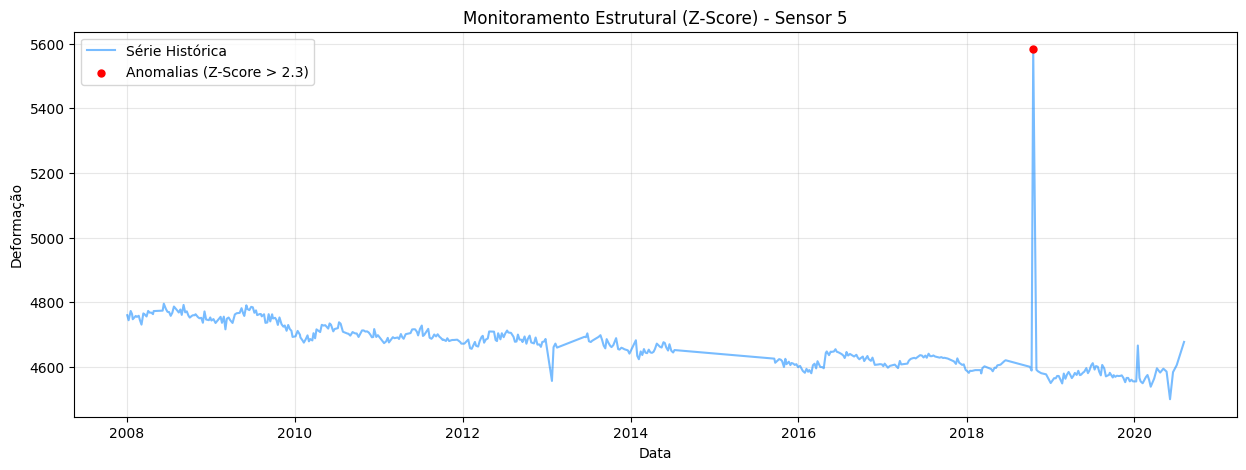

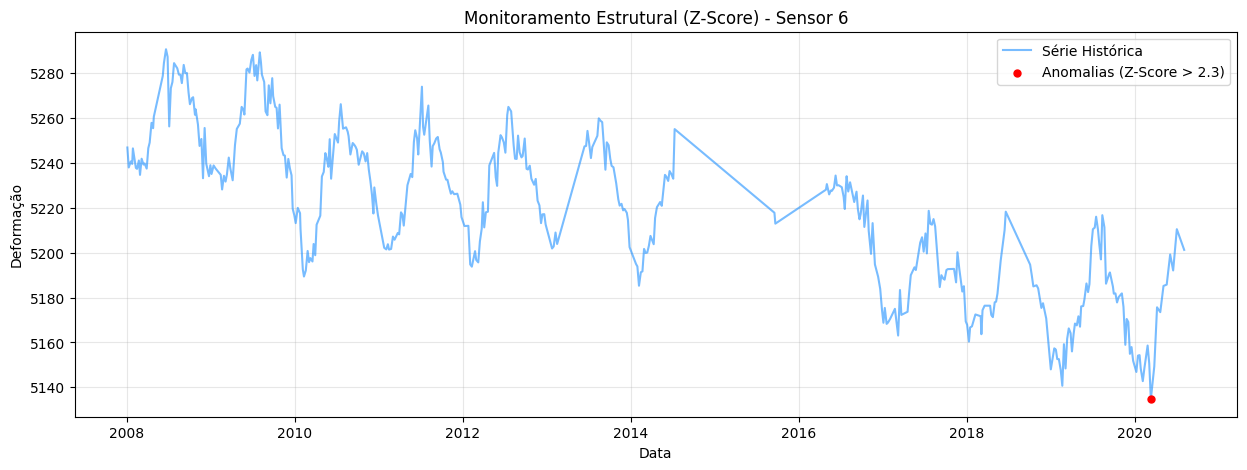

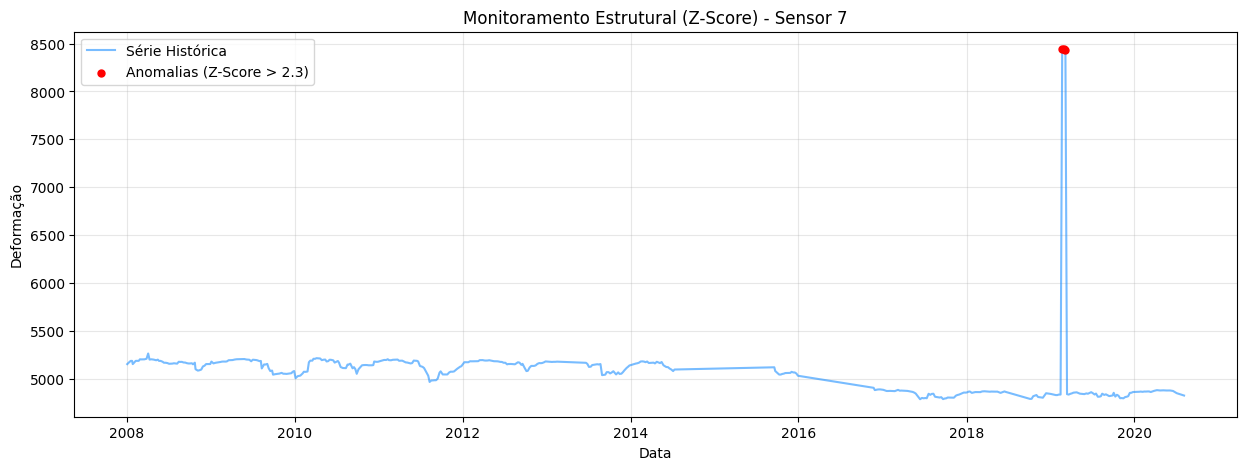

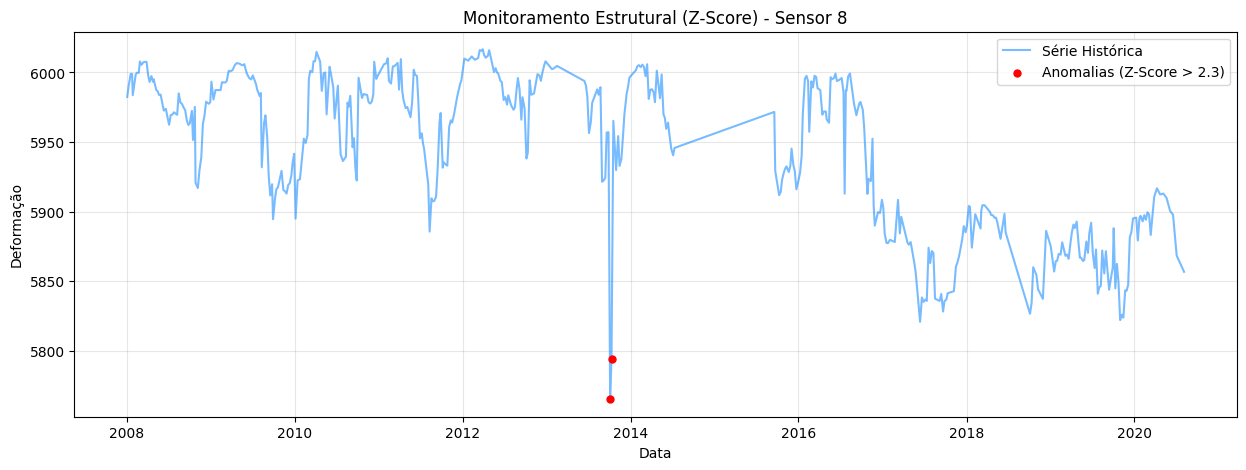

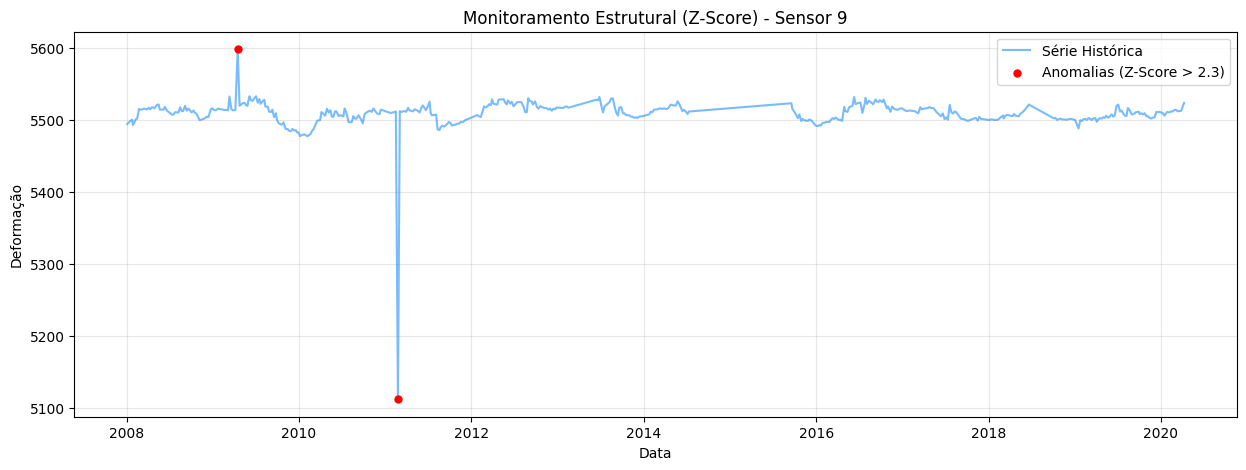

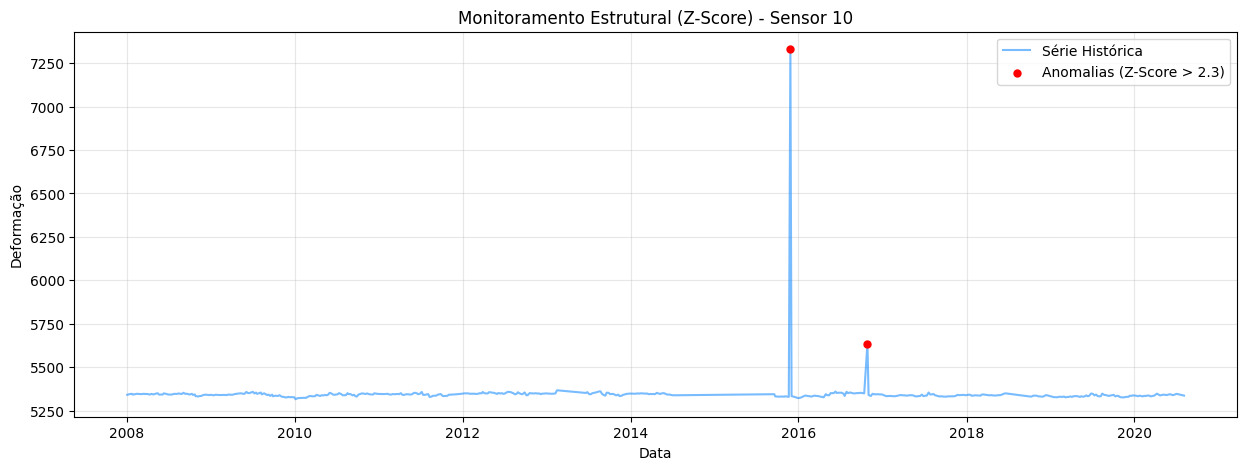

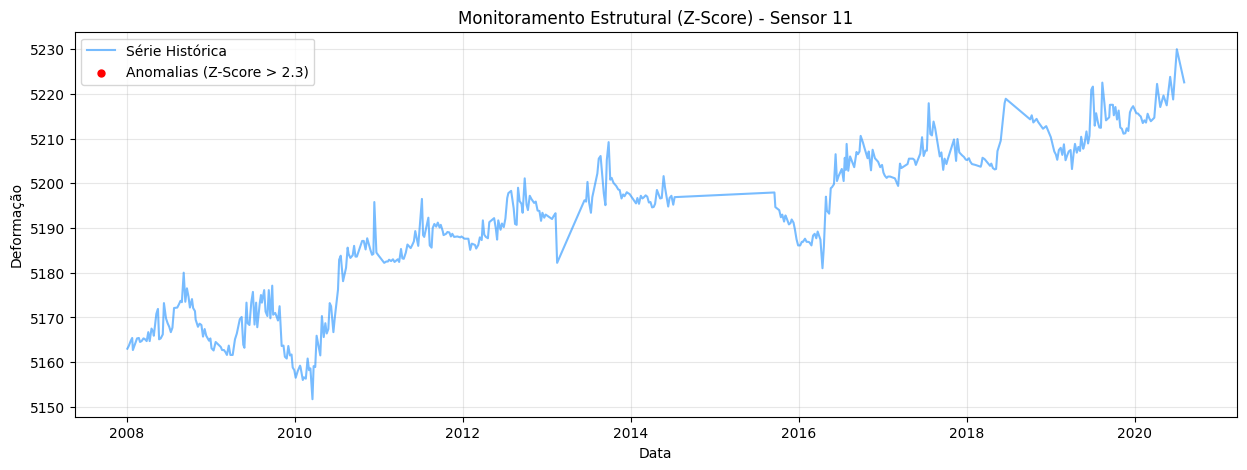

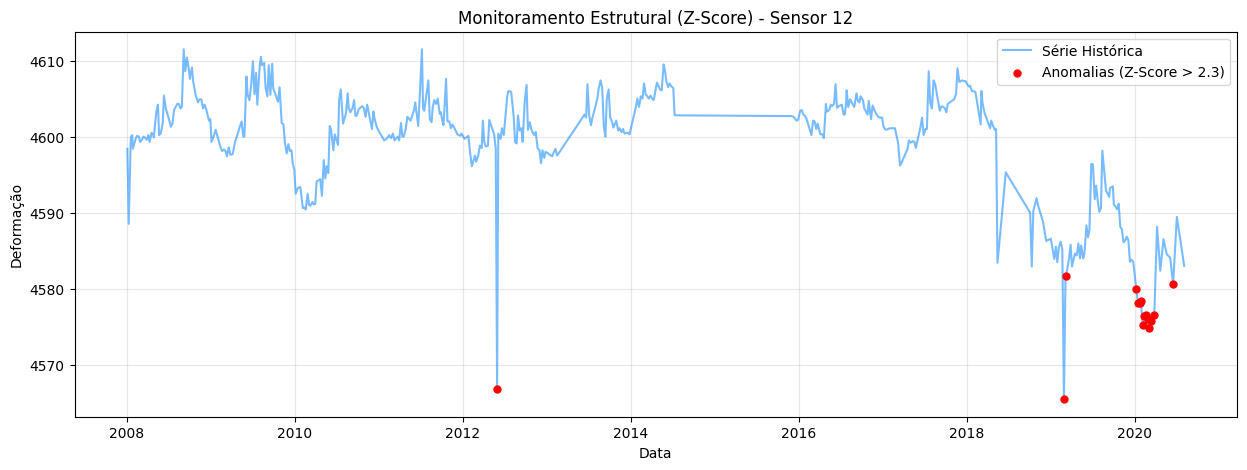

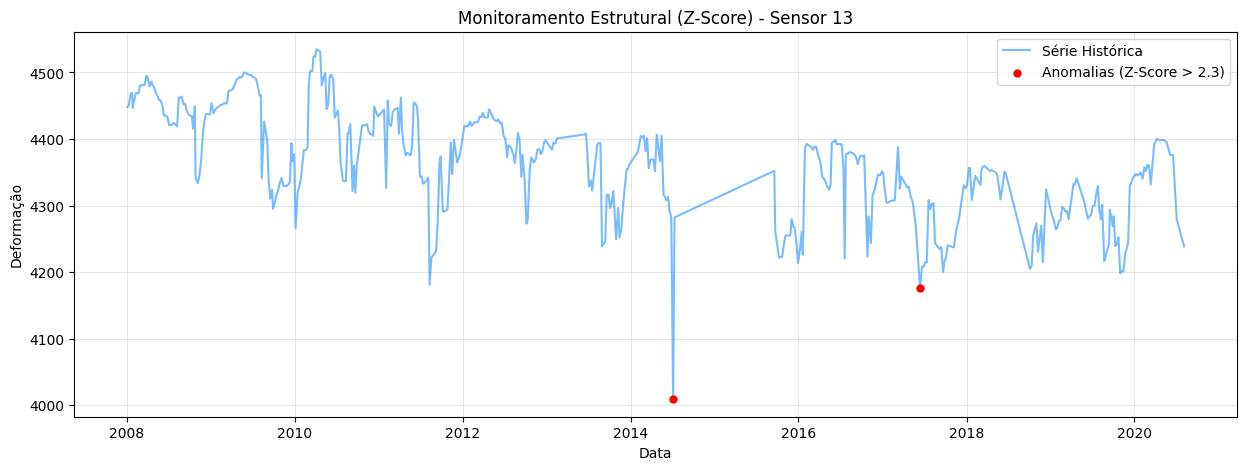

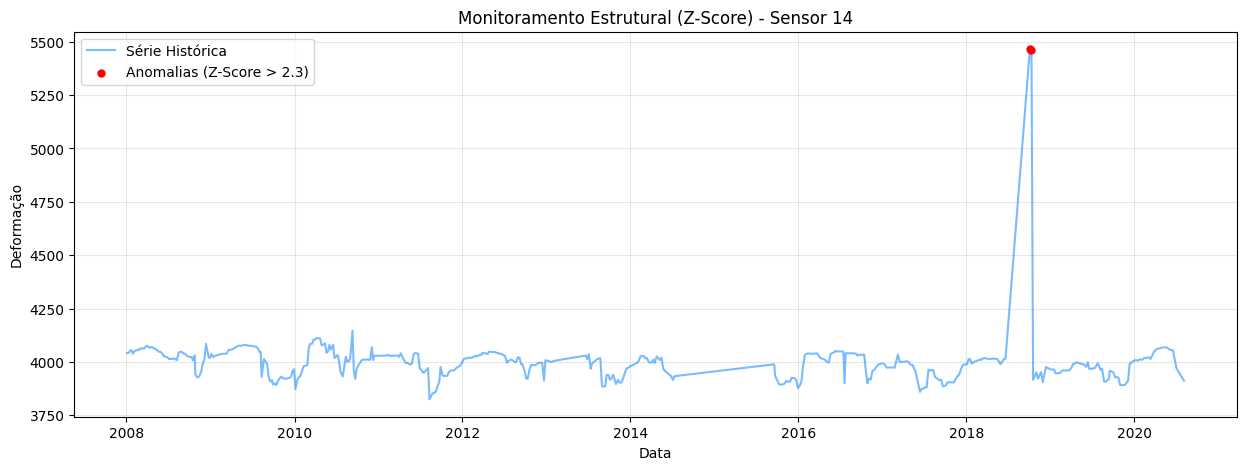

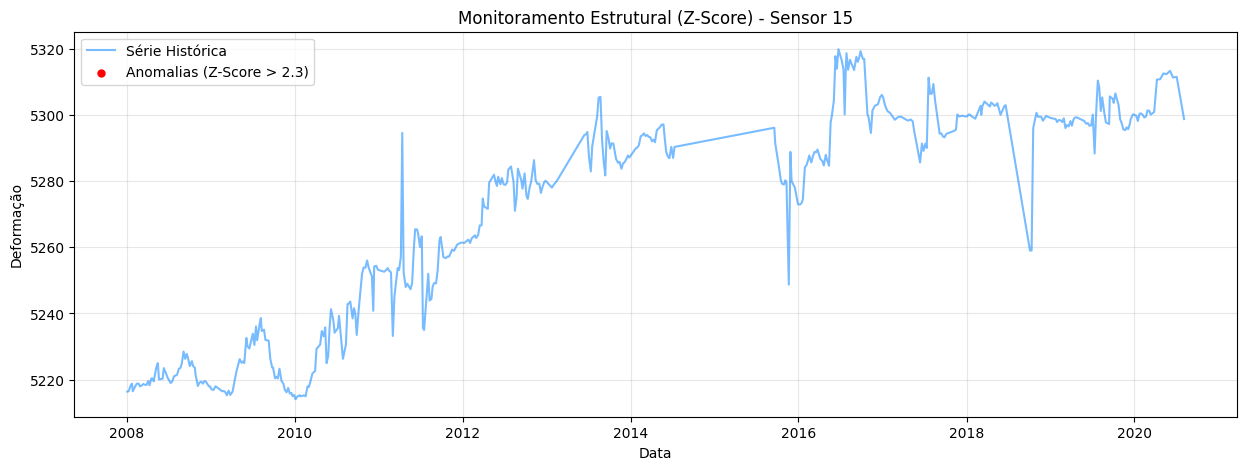

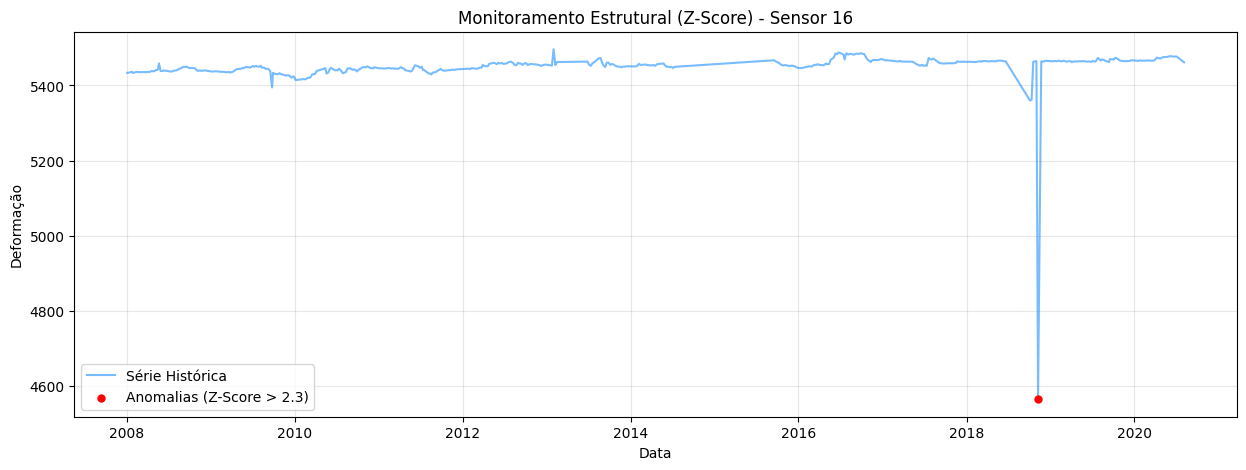

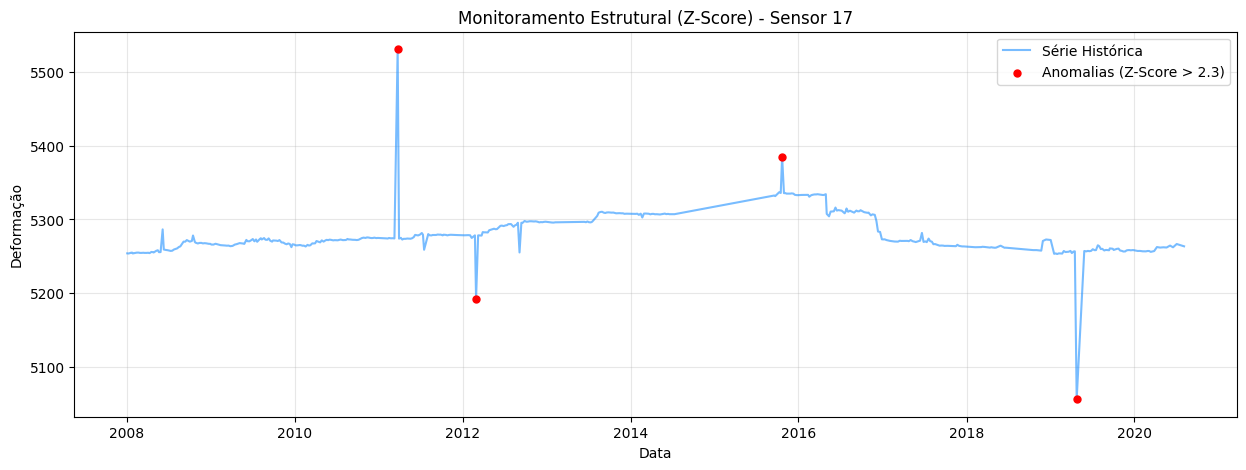

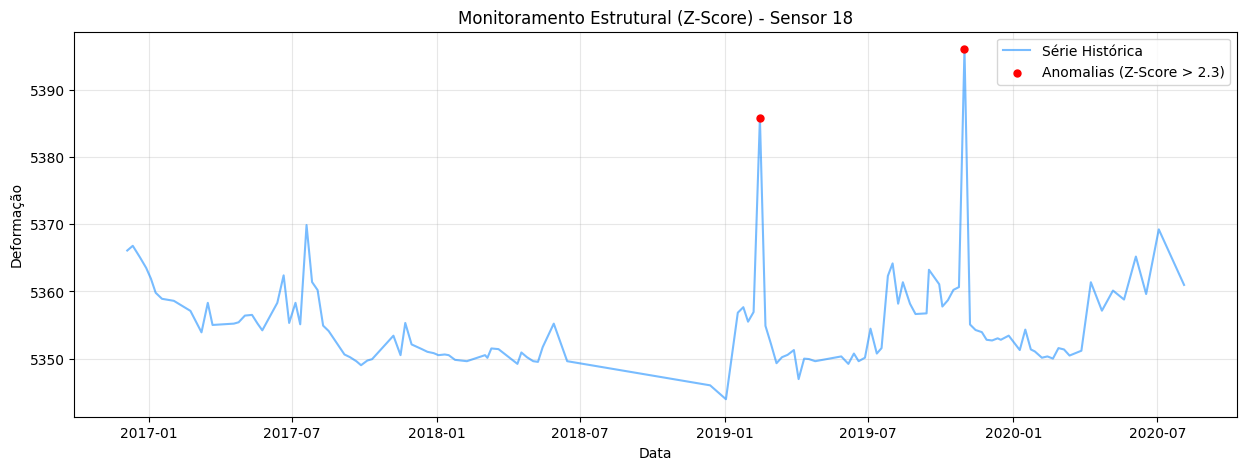

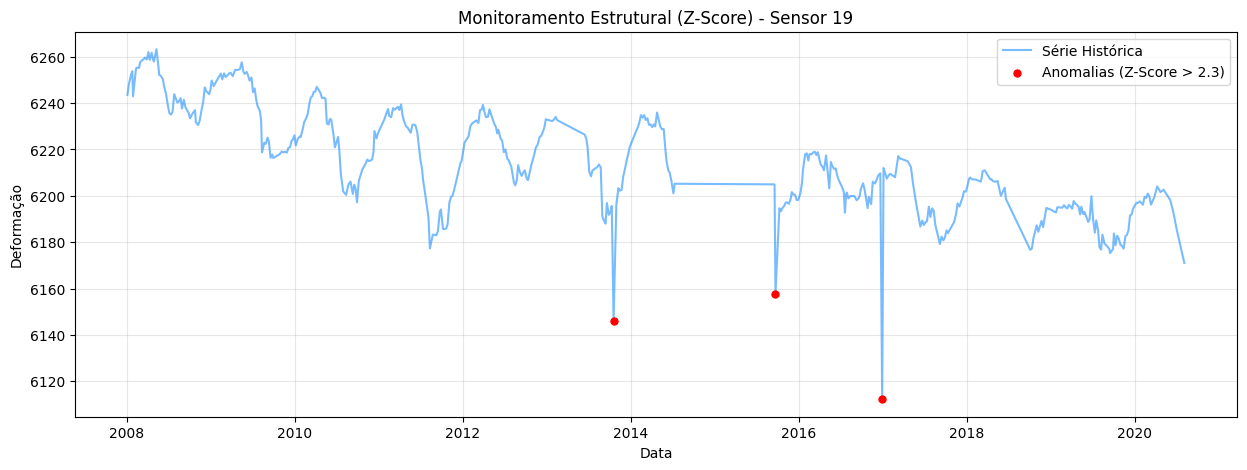

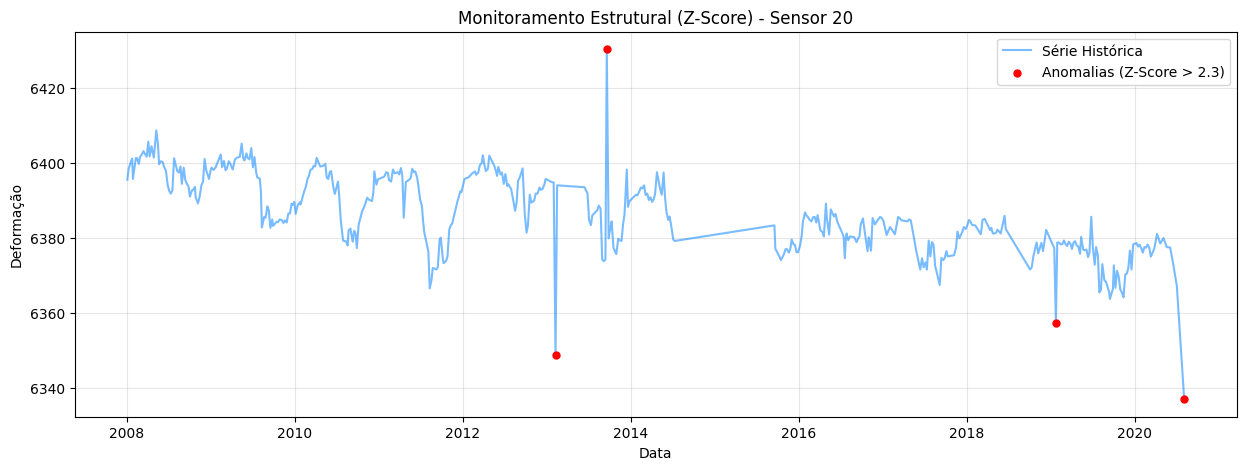

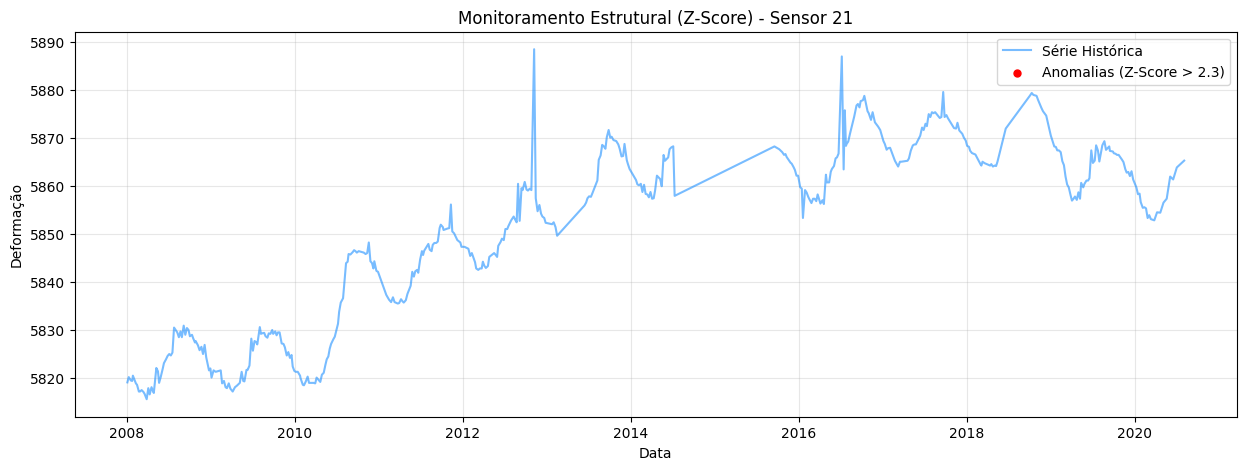

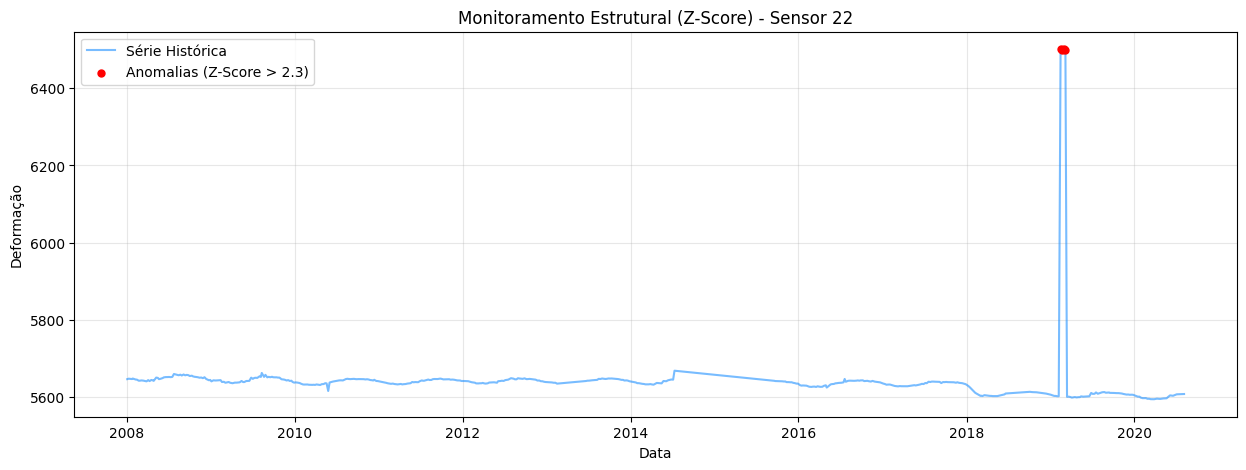

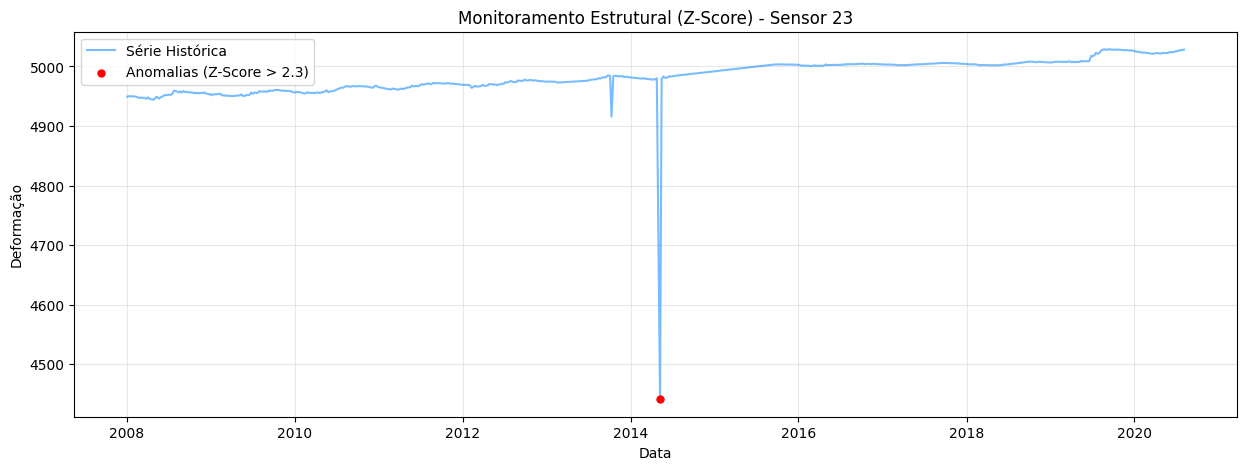

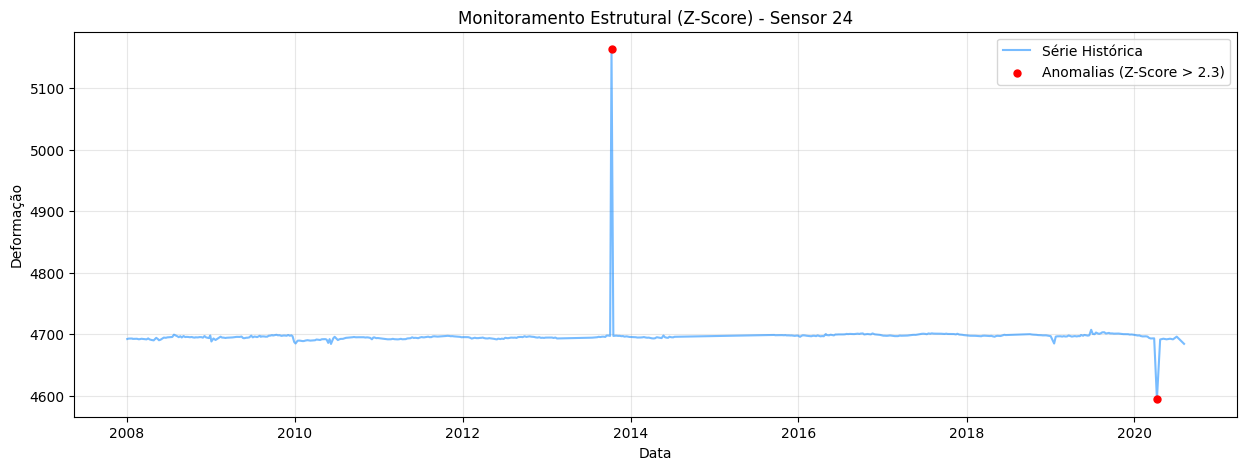

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_sensor_anomalies_zscore(df, sensor_id, threshold=0.5):
    df_plot = df[[sensor_id]].dropna()

    if df_plot.empty:
        print(f"Sensor {sensor_id} não possui dados para plotar.")
        return

    # Cálculo do Z-Score
    mean = df_plot[sensor_id].mean()
    std = df_plot[sensor_id].std()

    # Cálculo da distância de cada ponto em relação à média
    z_scores = np.abs((df_plot[sensor_id] - mean) / std)

    #Identificação de anomalias
    anomalies = df_plot[z_scores > threshold]

    # Plotagem
    plt.figure(figsize=(15, 5))

    # Série Histórica
    plt.plot(df_plot.index, df_plot[sensor_id], color='dodgerblue',
             label='Série Histórica', alpha=0.6)

    # Anomalias (Vermelho)
    plt.scatter(anomalies.index, anomalies[sensor_id], color='red',
                label=f'Anomalias (Z-Score > {threshold})', s=25, zorder=3)

    plt.title(f"Monitoramento Estrutural (Z-Score) - Sensor {sensor_id}")
    plt.ylabel("Deformação")
    plt.xlabel("Data")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

for col in df_daily.columns:
    # obs: ficar de olho no threshold
    plot_sensor_anomalies_zscore(df_daily, col, threshold=2.3)

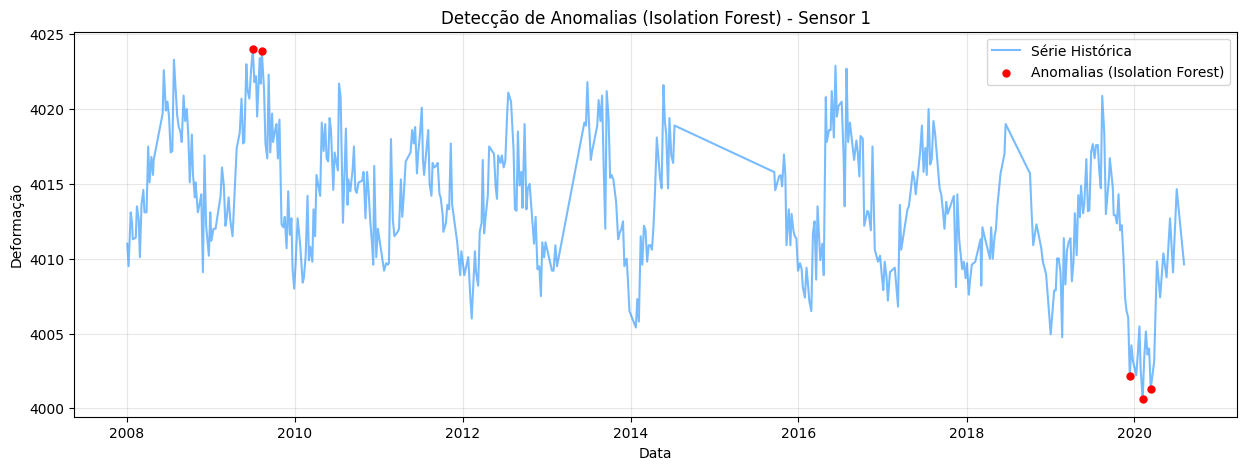

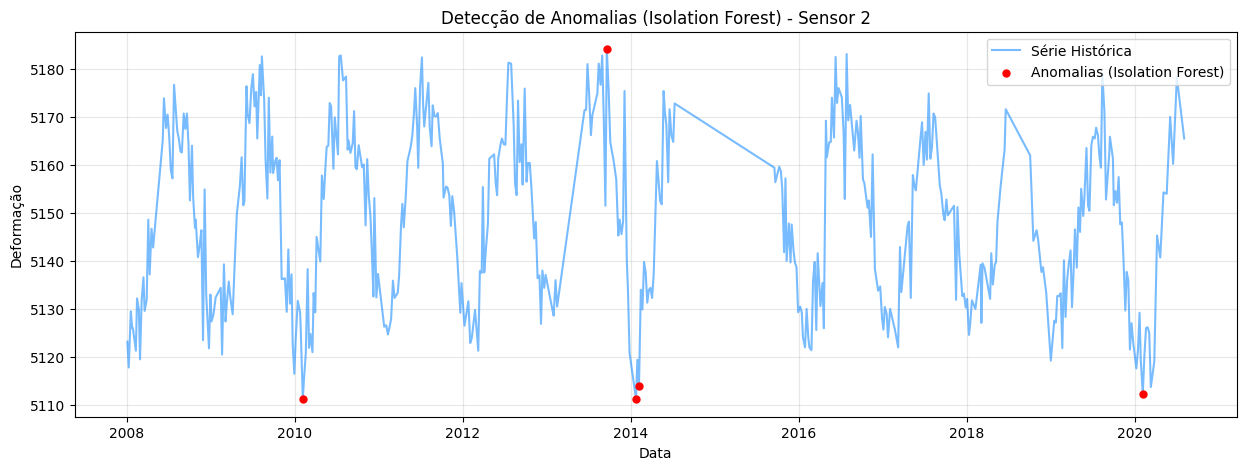

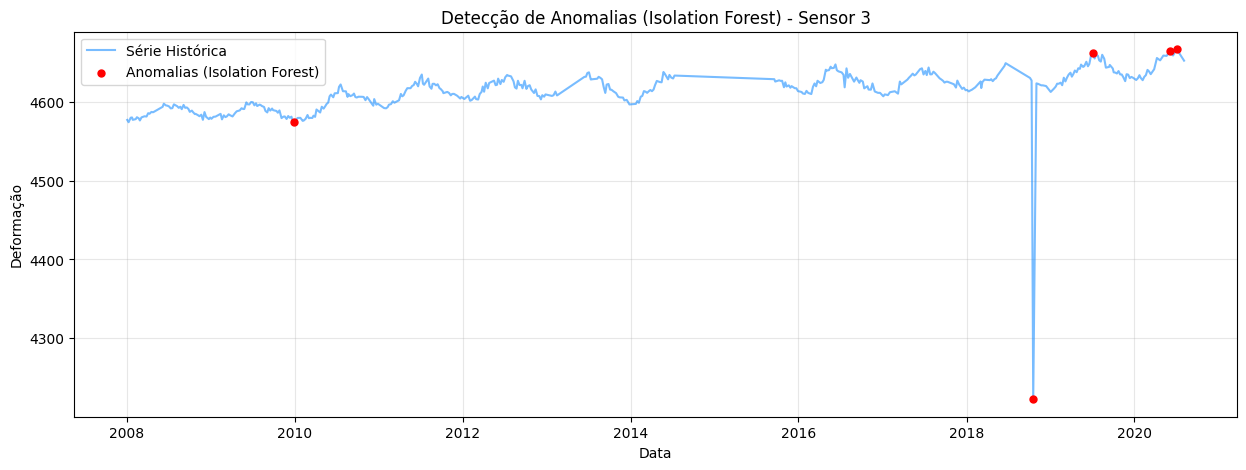

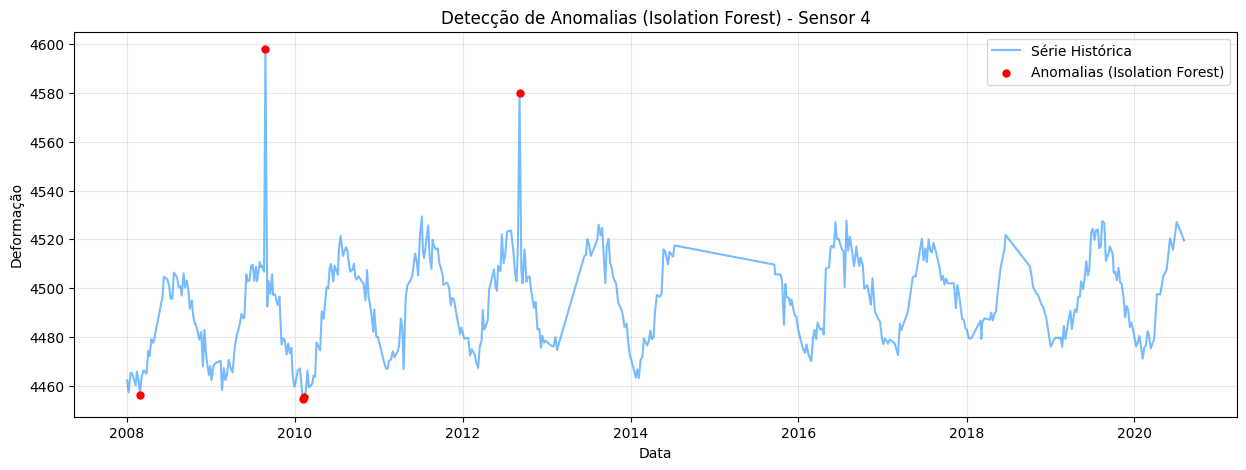

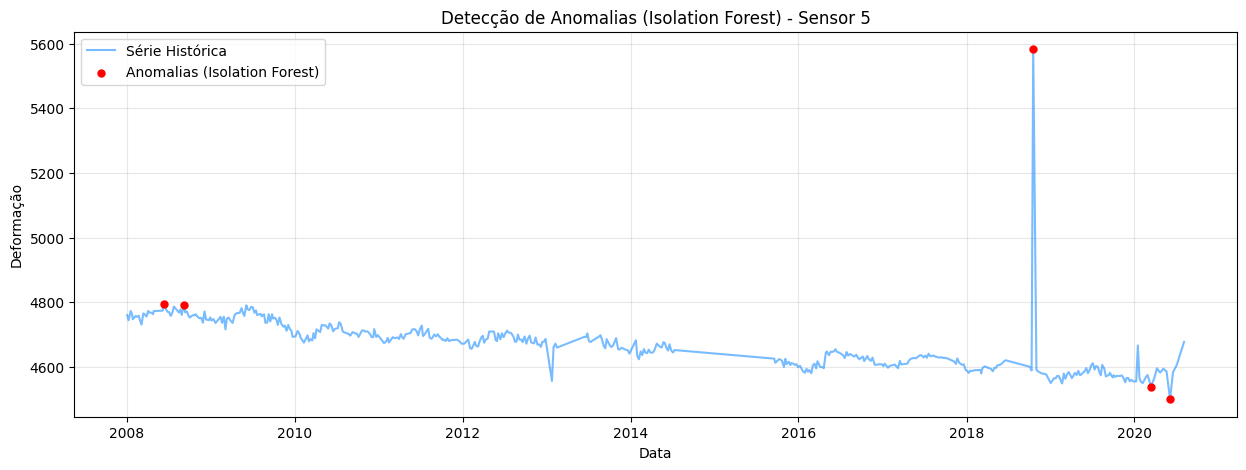

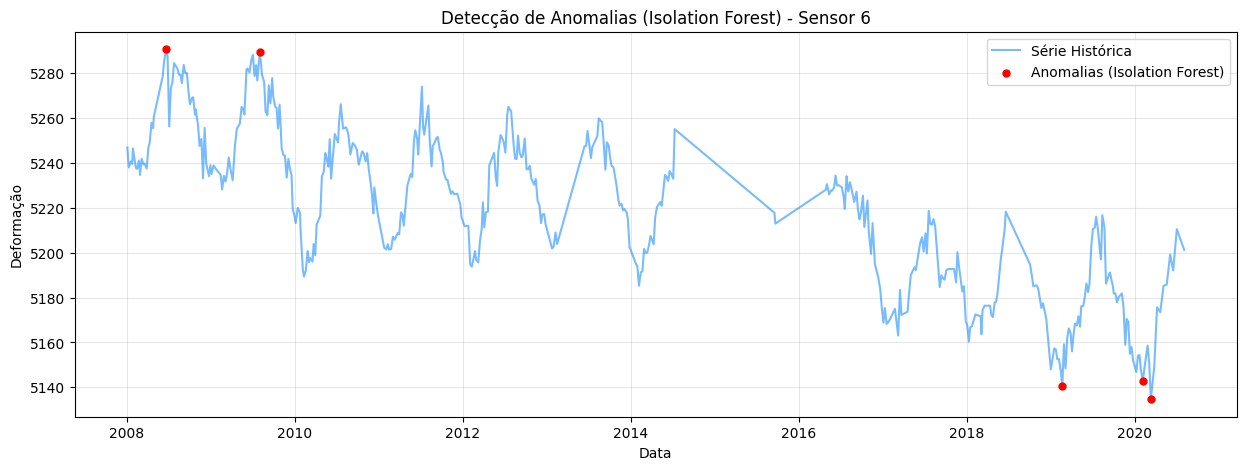

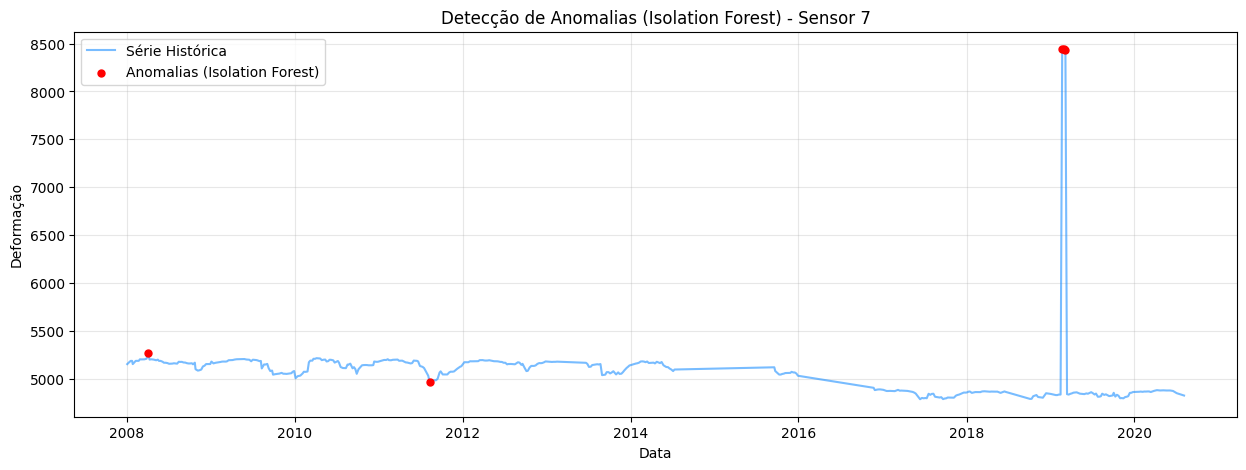

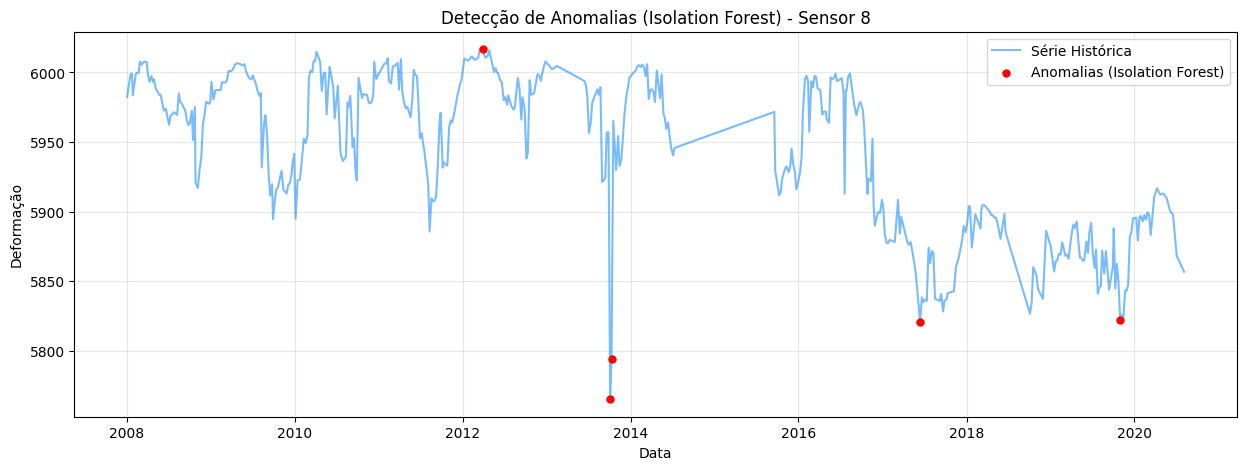

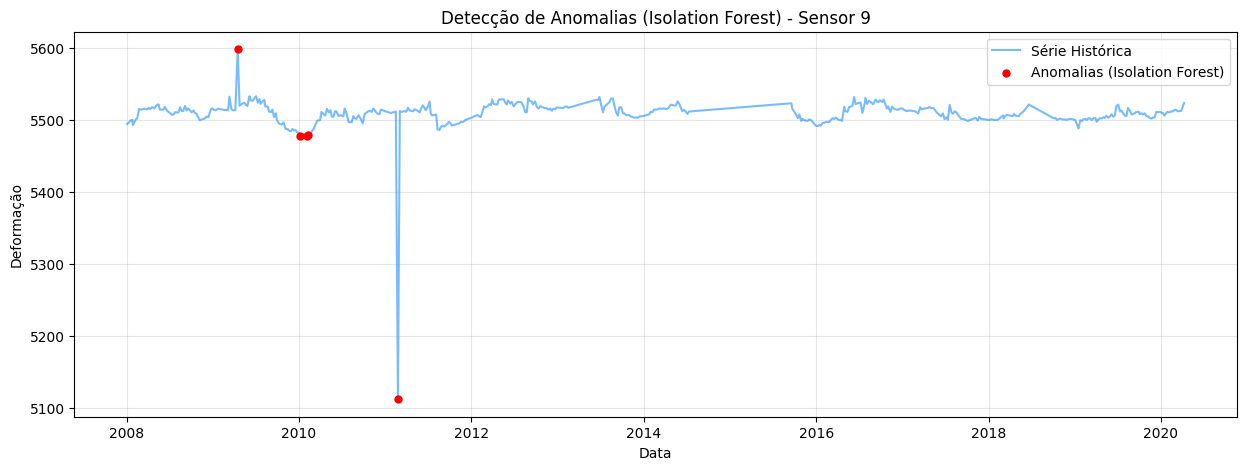

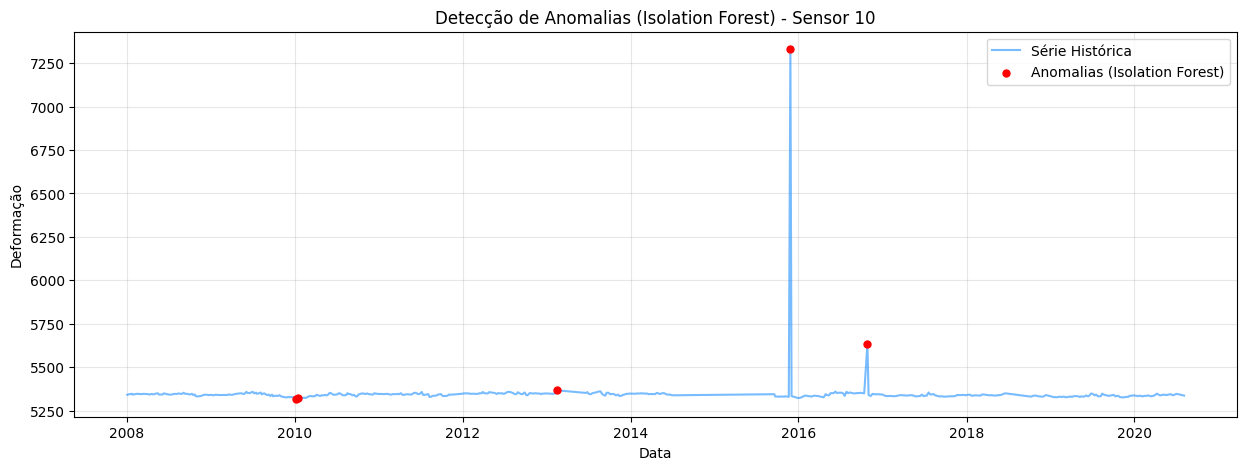

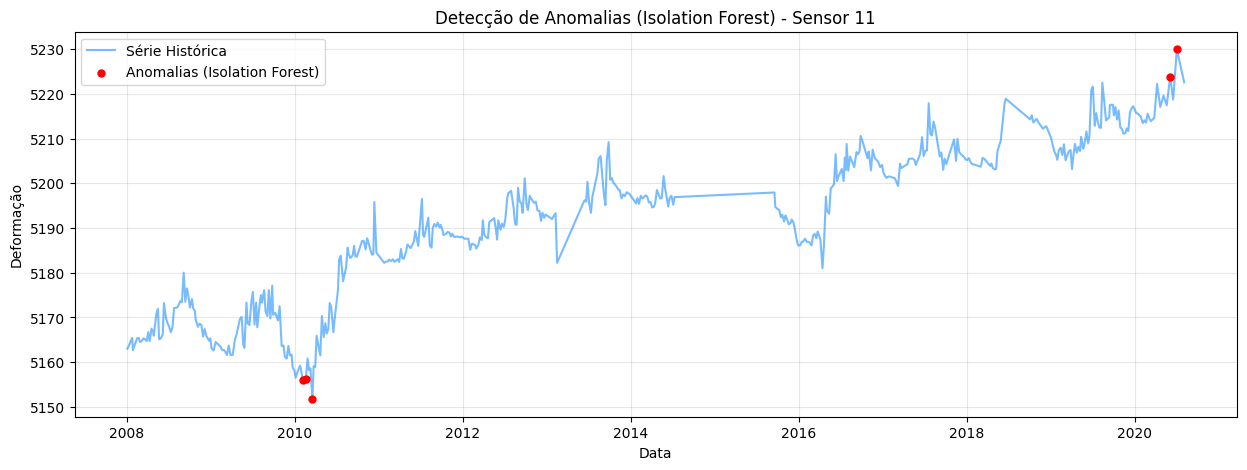

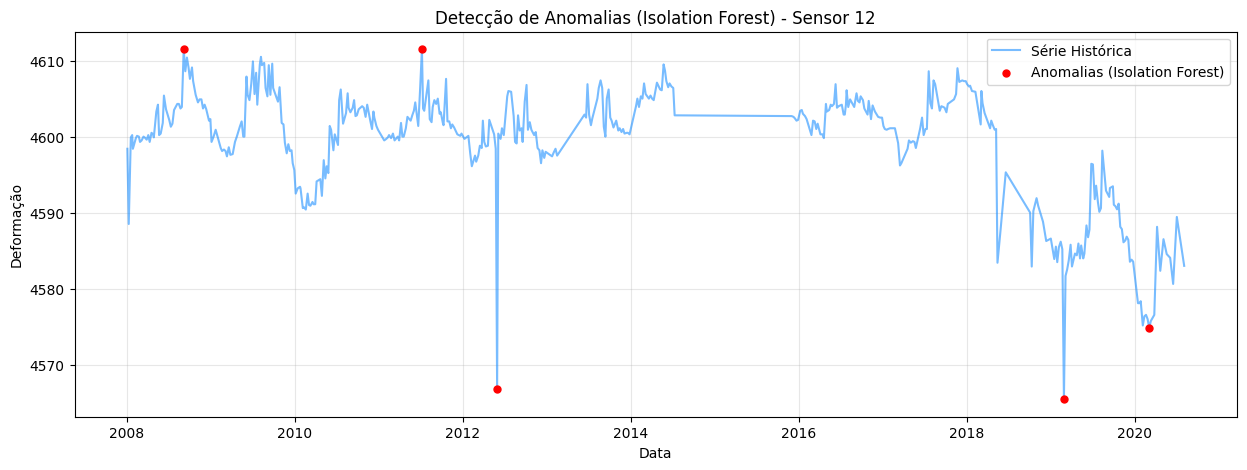

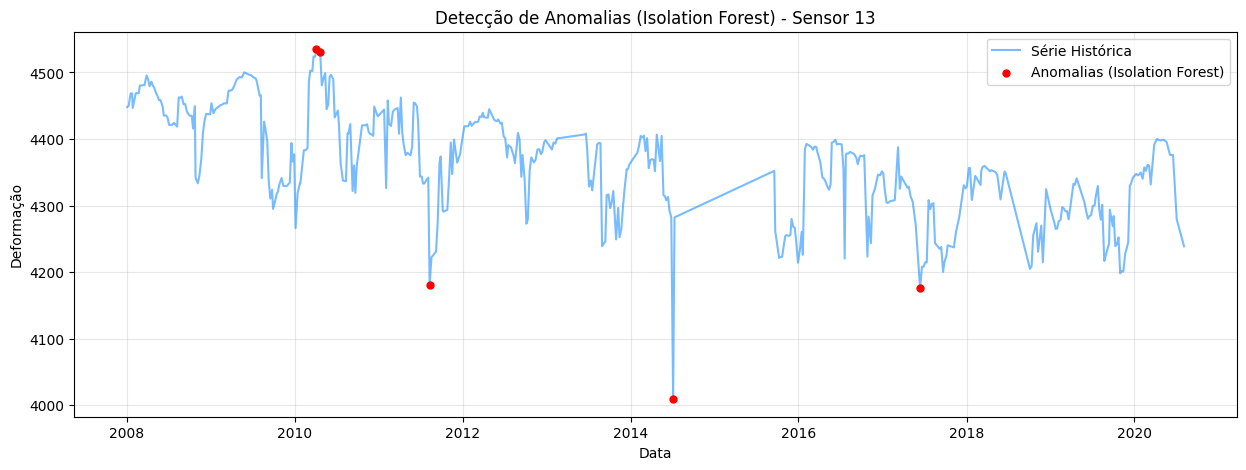

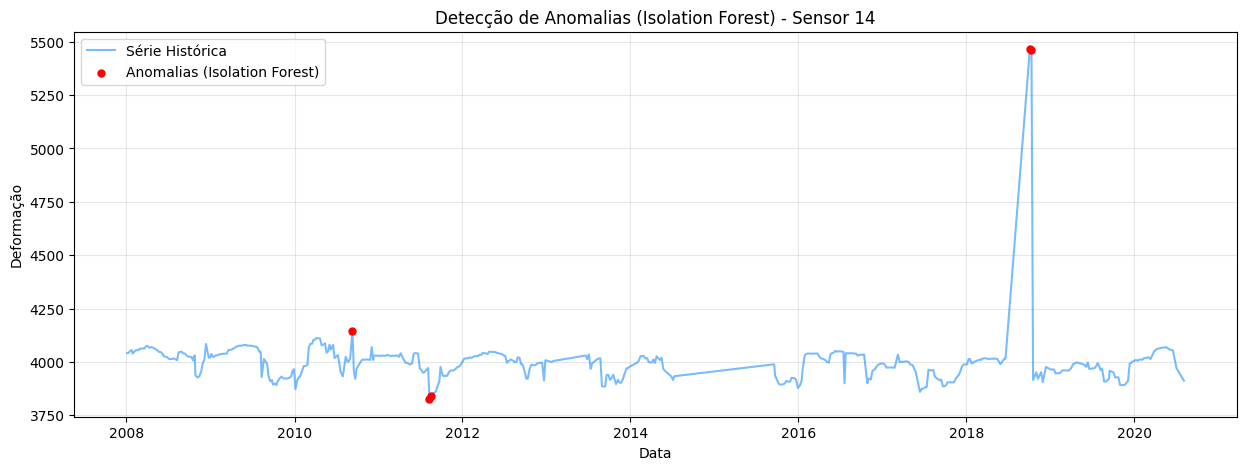

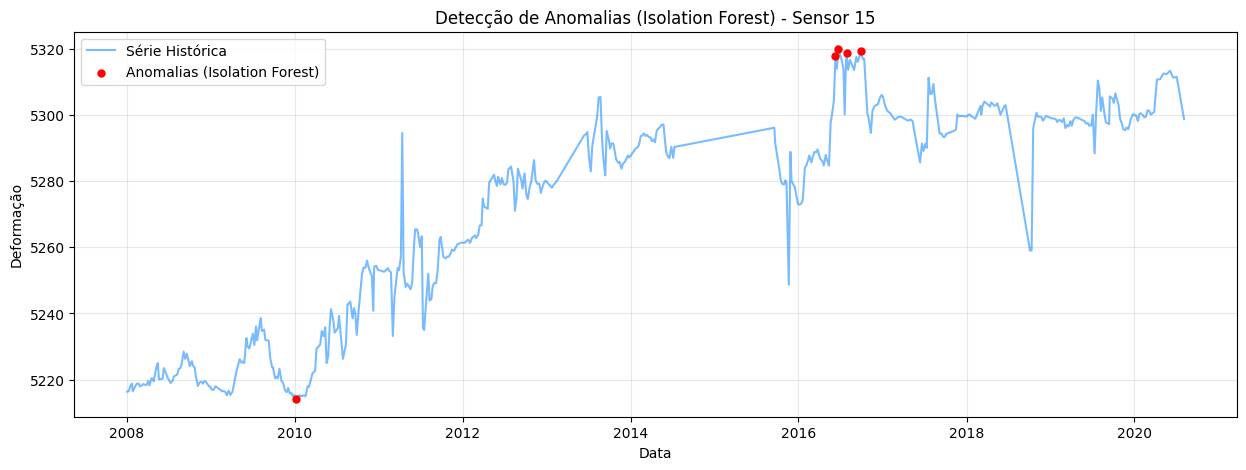

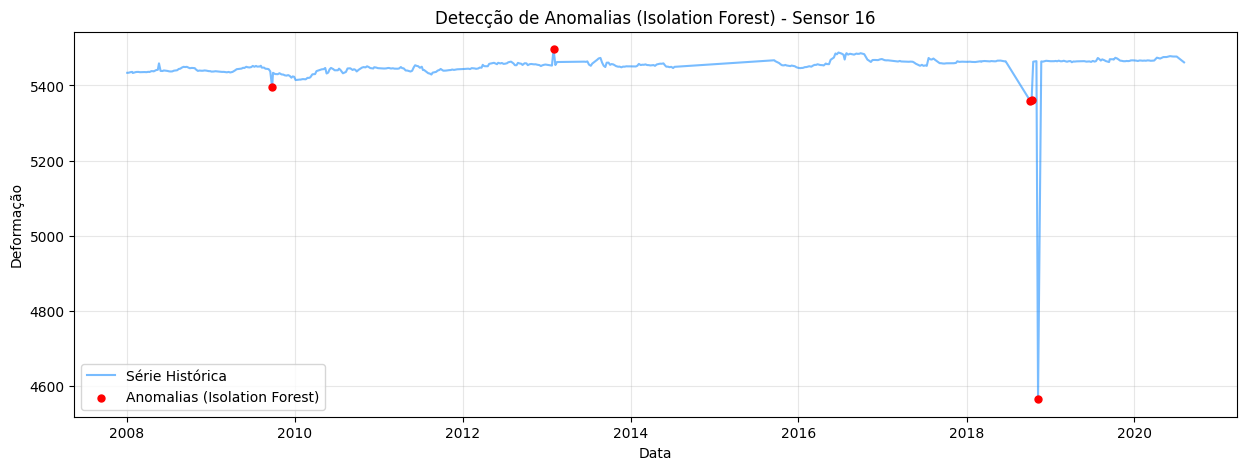

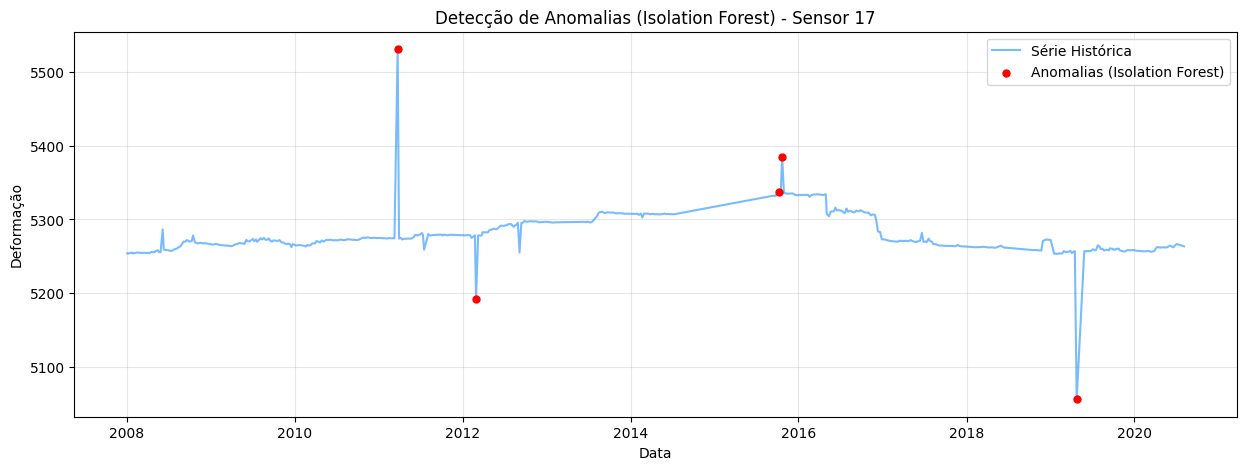

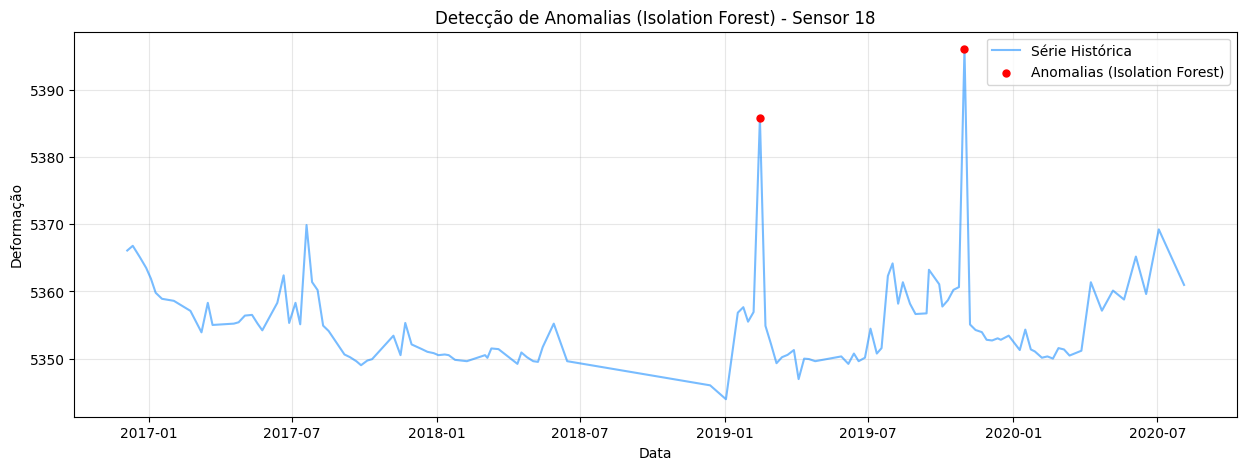

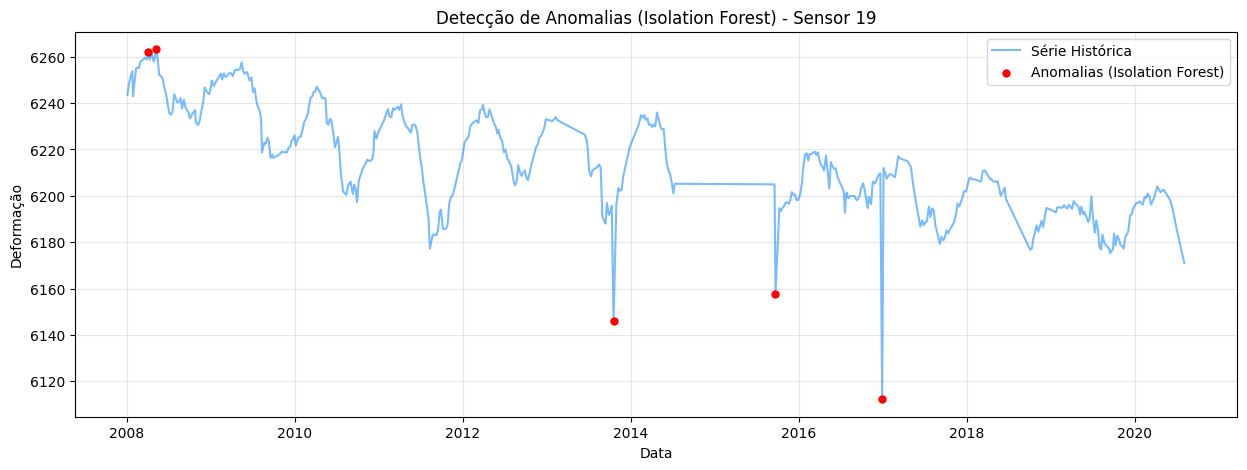

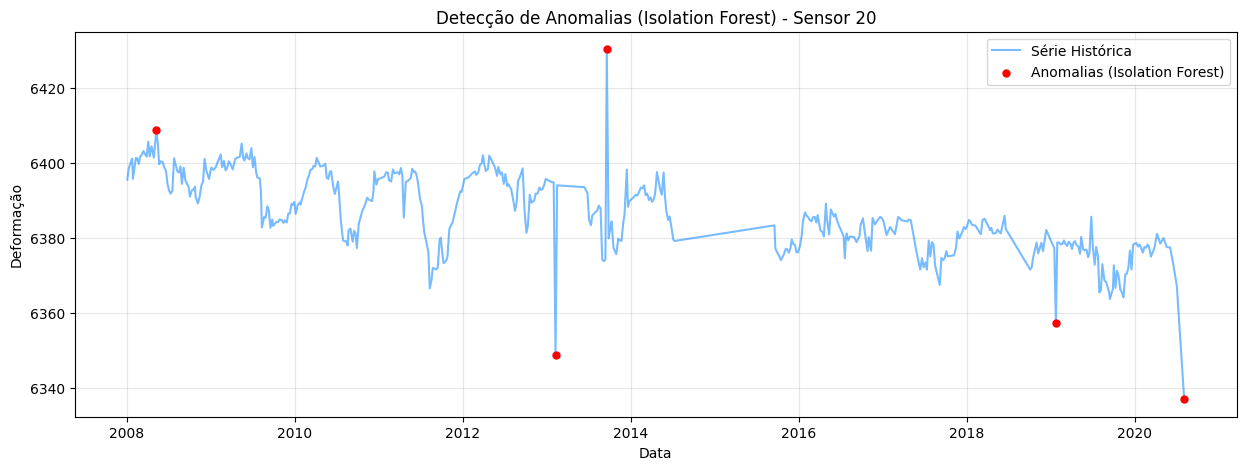

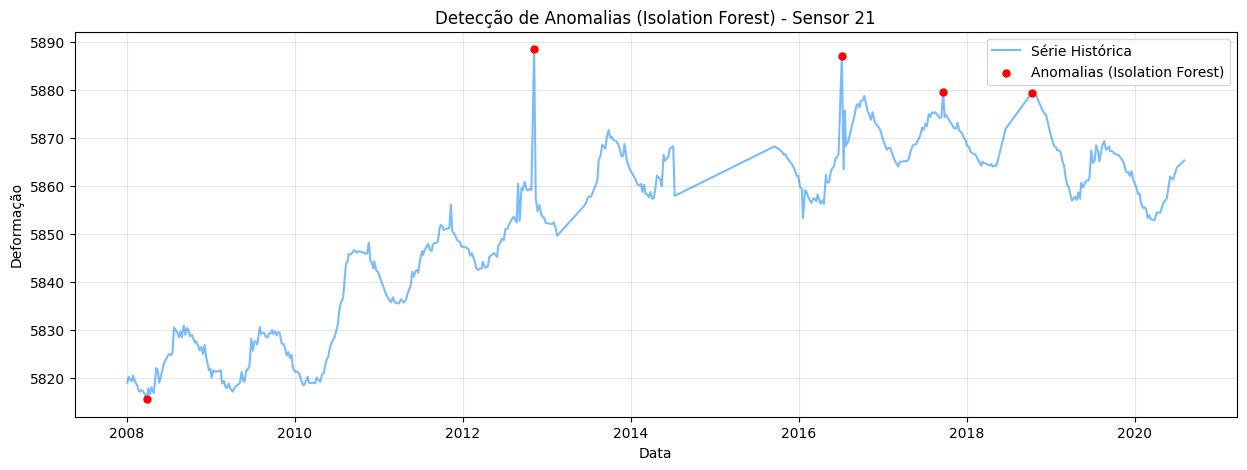

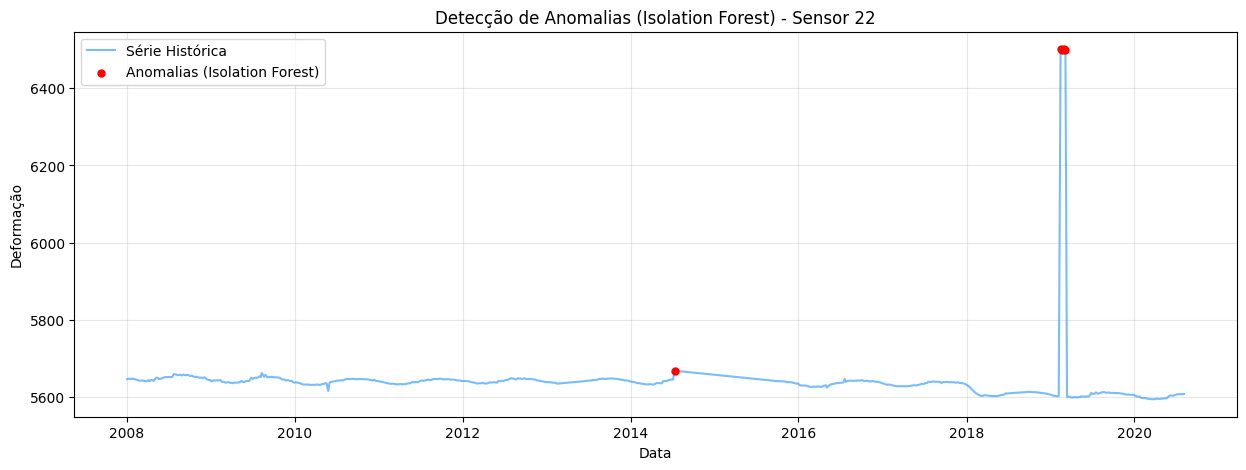

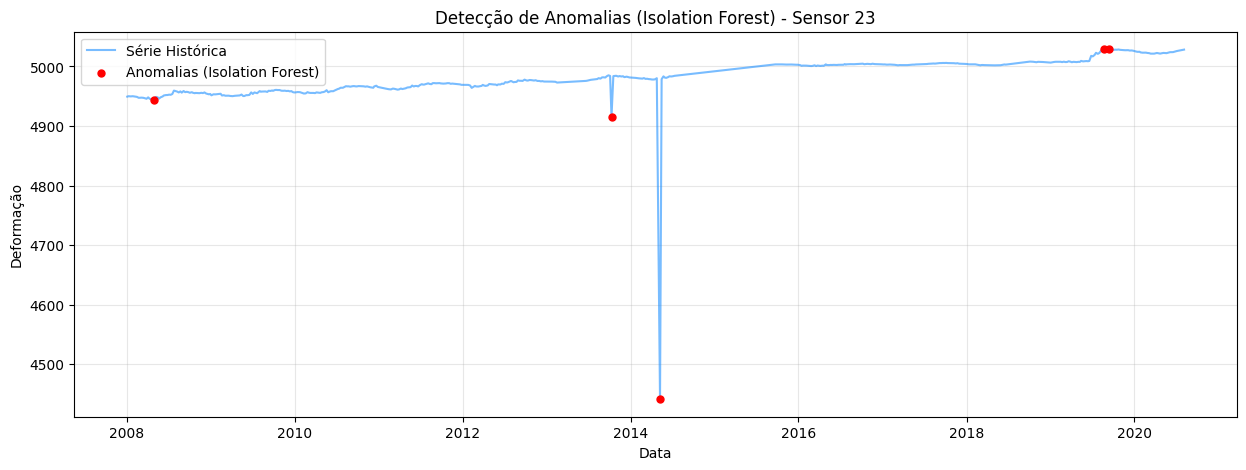

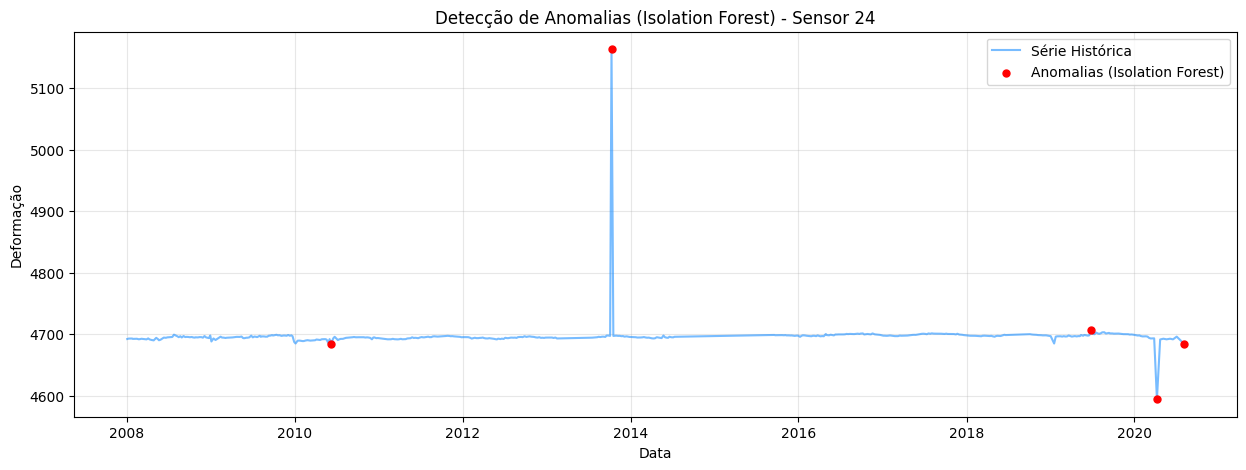

In [ ]:
from sklearn.ensemble import IsolationForest

def plot_sensor_anomalies_isolation_forest(df, sensor_id, contamination=0.01):
    df_plot = df[[sensor_id]].dropna()

    if df_plot.empty:
        print(f"Sensor {sensor_id} não possui dados.")
        return

    # 2. Configurar e Treinar o Modelo
    X = df_plot[[sensor_id]].values
    model = IsolationForest(contamination=contamination, random_state=42)


    preds = model.fit_predict(X)

    anomalies = df_plot[preds == -1]

    # Plotagem
    plt.figure(figsize=(15, 5))
    plt.plot(df_plot.index, df_plot[sensor_id], color='dodgerblue',
             label='Série Histórica', alpha=0.6)

    plt.scatter(anomalies.index, anomalies[sensor_id], color='red',
                label=f'Anomalias (Isolation Forest)', s=25, zorder=3)

    plt.title(f"Detecção de Anomalias (Isolation Forest) - Sensor {sensor_id}")
    plt.ylabel("Deformação")
    plt.xlabel("Data")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
for col in df_daily.columns:
# Testando com um sensor
   plot_sensor_anomalies_isolation_forest(df_daily, col, contamination=0.01)

In [ ]:
# Conta quantos dias ficaram totalmente sem leitura de sensor
dias_vazios = df_daily.isnull().all(axis=1).sum()
print(f"Existem {dias_vazios} dias sem nenhuma leitura no dataset.")

Existem 4110 dias sem nenhuma leitura no dataset.


##Limpeza e treino

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# 1. FILTRO TEMPORAL INICIAL (Apenas para delimitar o estudo)
df_estudo = df_daily.copy()
sensor_col = 1  # Definindo a coluna do sensor

# 2. SPLIT TREINO/TESTE (O primeiro passo para evitar vazamento)
split_idx = int(0.8 * len(df_estudo))
train_data = df_estudo.iloc[:split_idx].copy()
test_data = df_estudo.iloc[split_idx:].copy()

# 3. LIMPEZA DE OUTLIERS (Isolation Forest aplicado apenas no Treino)
X_iso = train_data[[sensor_col]].dropna().values
iso_forest = IsolationForest(contamination=0.01, random_state=42)
iso_forest.fit(X_iso)

# Marcar anomalias como NaN no treino
preds_train = iso_forest.predict(train_data[[sensor_col]].values)
train_data.loc[preds_train == -1, sensor_col] = np.nan

# 4. TRATAMENTO DE NANS E SUAVIZAÇÃO
train_data = train_data.interpolate(method='linear').bfill().ffill()
train_suave = train_data[sensor_col].rolling(window=7, center=False).mean().bfill().ffill()

# 5. NORMALIZAÇÃO
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_suave.values.reshape(-1, 1))


In [ ]:

# LIMPEZA E SUAVIZAÇÃO DO TESTE
preds_test = iso_forest.predict(test_data[[sensor_col]].fillna(method='ffill').values)
test_data.loc[preds_test == -1, sensor_col] = np.nan

# Interpolação e Suavização
test_data = test_data.interpolate(method='linear').bfill().ffill()
test_suave = test_data[sensor_col].rolling(window=7, center=False).mean().bfill().ffill()

#  NORMALIZAÇÃO DO TESTE
test_scaled = scaler.transform(test_suave.values.reshape(-1, 1))

# 8. CRIAÇÃO DAS SEQUÊNCIAS (Lookback)
def create_sequences(data, lookback, horizon=7):
    X, y = [], []
    for i in range(len(data) - lookback - horizon + 1):
        X.append(data[i : i + lookback])
        y.append(data[i + lookback + horizon - 1])
    return np.array(X), np.array(y)

lookback = 60
X_train, y_train = create_sequences(train_scaled, lookback)
X_test, y_test = create_sequences(test_scaled, lookback)

print(f"Treino: {X_train.shape}, Teste: {X_test.shape}")

Treino: (3611, 60, 1), Teste: (854, 60, 1)


/tmp/ipykernel_1028/1757776258.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  preds_test = iso_forest.predict(test_data[[sensor_col]].fillna(method='ffill').values)


##Dois sensores

In [ ]:
import numpy as np
import pandas as pd

def calcular_tlsc(df, sensor_alvo, sensor_influencia, max_lag=30):
    # 1. Garantir que não existam NaNs antes de começar
    # Usamos interpolação para preencher buracos deixados pelo Isolation Forest
    s1 = df[sensor_alvo].interpolate().ffill().bfill()
    s2 = df[sensor_influencia].interpolate().ffill().bfill()

    lags = range(-max_lag, max_lag + 1)
    correlacoes = []

    for lag in lags:
        # 2. Deslocamos o sensor de influência
        s2_shifted = s2.shift(lag)

        # 3. Calculamos a correlação ignorando os novos NaNs criados pelo shift
        # O Spearman precisa que ambas as séries tenham variação (std > 0)
        if s1.std() == 0 or s2_shifted.std() == 0:
            corr = 0
        else:
            corr = s1.corr(s2_shifted, method='spearman')

        correlacoes.append(corr)

    return np.array(lags), np.array(correlacoes)

# Execução
lags, corrs = calcular_tlsc(df_recortado, 1, 22, max_lag=20)

# 4. Tratar caso todos os resultados ainda sejam NaN (por segurança)
if np.all(np.isnan(corrs)):
    print("Erro: Todas as correlações retornaram NaN. Verifique se os dados não são constantes.")
else:
    # Usamos nanargmax para ignorar possíveis NaNs restantes
    idx = np.nanargmax(np.abs(corrs))
    best_lag = lags[idx]
    max_corr = corrs[idx]

    print(f"Melhor Lag: {best_lag} dias")
    print(f"Correlação de Spearman no melhor lag: {max_corr:.4f}")

Melhor Lag: -20 dias
Correlação de Spearman no melhor lag: 0.5946


<Figure size 1200x600 with 0 Axes>

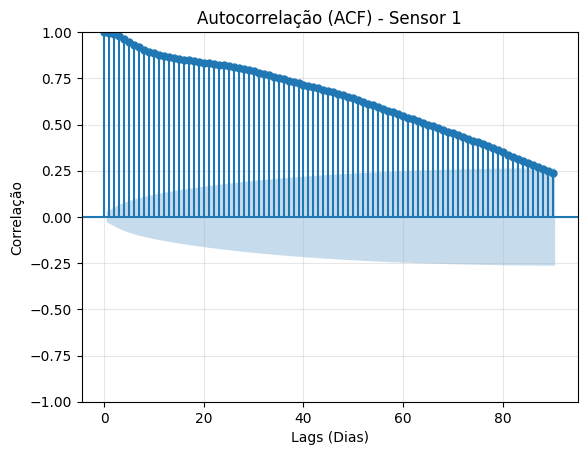

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

# Escolha o sensor e o número de lags (dias de atraso)
sensor_id = 1
lags = 90  # Vamos olhar a correlação nos últimos 3 meses

# Importante: A autocorrelação não aceita NaNs
dados_limpos = df_daily[sensor_id].interpolate().bfill().ffill()

plt.figure(figsize=(12, 6))
plot_acf(dados_limpos, lags=lags, alpha=0.05) # alpha 0.05 é o intervalo de confiança de 95%
plt.title(f"Autocorrelação (ACF) - Sensor {sensor_id}")
plt.xlabel("Lags (Dias)")
plt.ylabel("Correlação")
plt.grid(True, alpha=0.3)
plt.show()

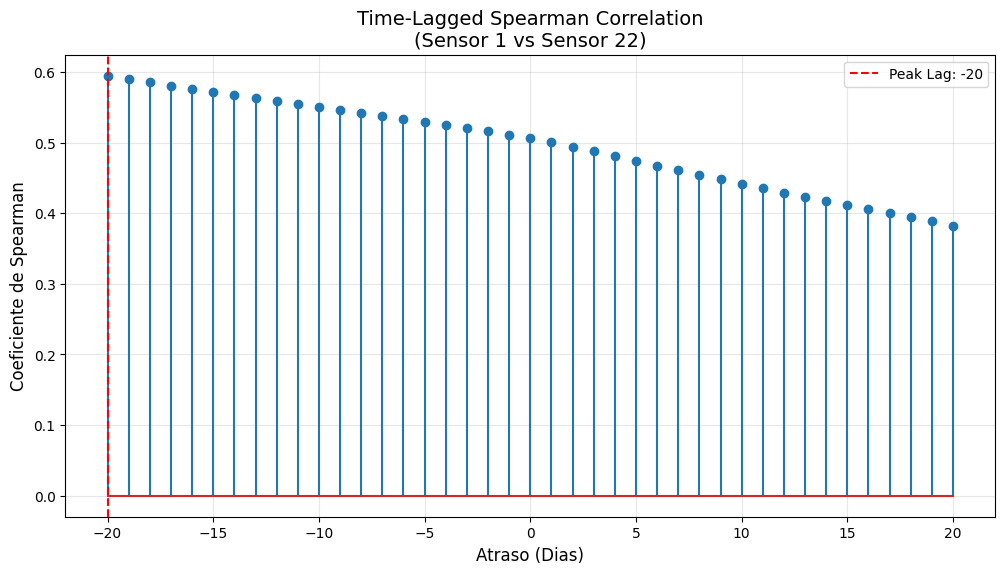

In [ ]:
plt.figure(figsize=(12, 6))
plt.stem(lags, corrs)
plt.axvline(x=best_lag, color='red', linestyle='--', label=f'Peak Lag: {best_lag}')

plt.title(f"Time-Lagged Spearman Correlation\n(Sensor 1 vs Sensor 22)", fontsize=14)
plt.xlabel("Atraso (Dias)", fontsize=12)
plt.ylabel("Coeficiente de Spearman", fontsize=12)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


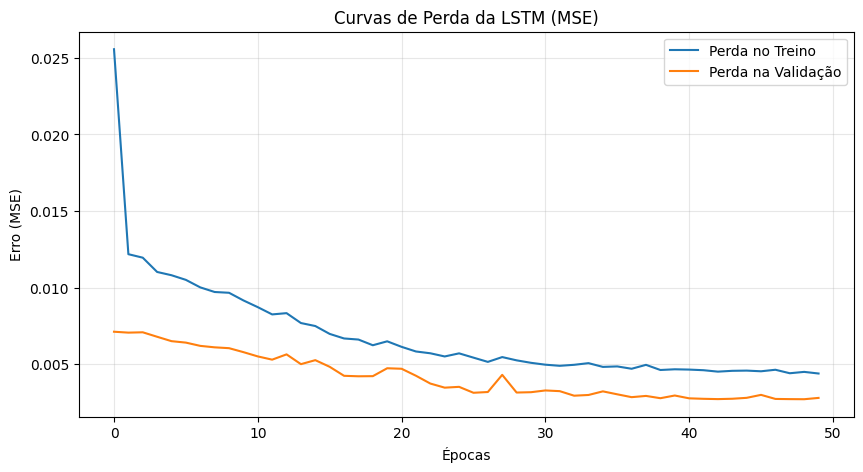

Treinando XGBoost...
Treinando Random Forest...


/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


RandomForestRegressor()

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

model_lstm = Sequential([
    LSTM(64, input_shape=(lookback, 1)),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1)
])
model_lstm.compile(optimizer='adam', loss='mse')

history = model_lstm.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=50,
    batch_size=32,
    verbose=0
)

plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Perda no Treino')
plt.plot(history.history['val_loss'], label='Perda na Validação')
plt.title("Curvas de Perda da LSTM (MSE)")
plt.xlabel("Épocas")
plt.ylabel("Erro (MSE)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

X_train_2d = X_train.reshape(X_train.shape[0], X_train.shape[1])
X_test_2d = X_test.reshape(X_test.shape[0], X_test.shape[1])

print("Treinando XGBoost...")
model_xgb = XGBRegressor(n_estimators=100, learning_rate=0.05)
model_xgb.fit(X_train_2d, y_train)

print("Treinando Random Forest...")
model_rf = RandomForestRegressor(n_estimators=100)
model_rf.fit(X_train_2d, y_train)

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Métricas de Comparação (Horizonte de 7 dias):
--------------------------------------------------
LSTM            | MAE: 0.0417 | RMSE: 0.0517 | R2: 0.9429
XGBoost         | MAE: 0.0662 | RMSE: 0.0868 | R2: 0.8391
Random Forest   | MAE: 0.0632 | RMSE: 0.0812 | R2: 0.8593


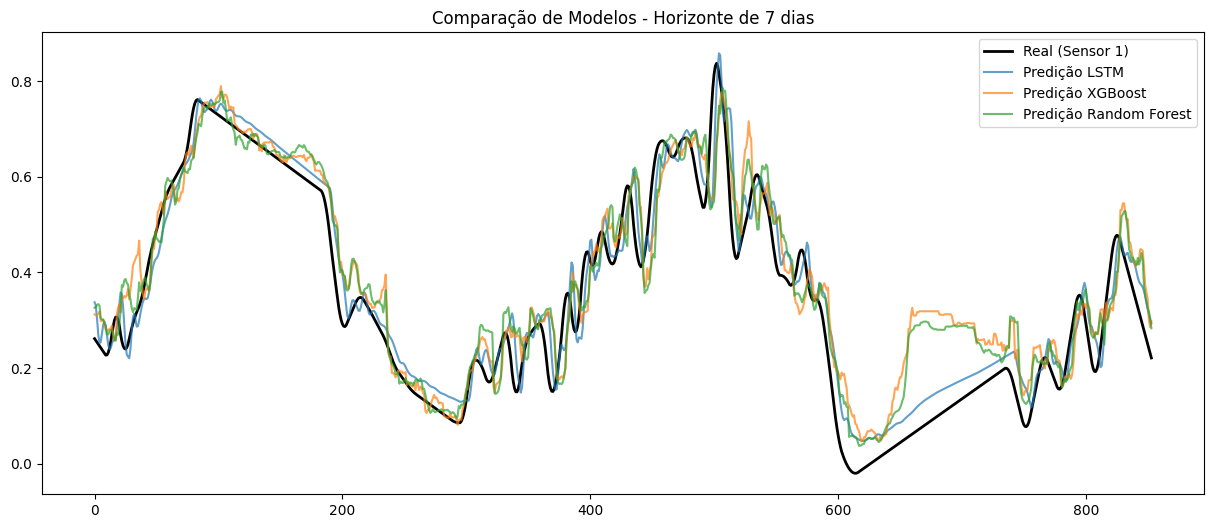

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# Predições
pred_lstm = model_lstm.predict(X_test)
pred_xgb = model_xgb.predict(X_test_2d)
pred_rf = model_rf.predict(X_test_2d)

# Função para calcular métricas
def avaliar(y_true, y_pred, nome):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{nome:15} | MAE: {mae:.4f} | RMSE: {rmse:.4f} | R2: {r2:.4f}")
    return mae, rmse, r2

print("Métricas de Comparação (Horizonte de 7 dias):")
print("-" * 50)
avaliar(y_test, pred_lstm, "LSTM")
avaliar(y_test, pred_xgb, "XGBoost")
avaliar(y_test, pred_rf, "Random Forest")

# Plotagem do resultado
plt.figure(figsize=(15, 6))
plt.plot(y_test, label='Real (Sensor 1)', color='black', linewidth=2)
plt.plot(pred_lstm, label='Predição LSTM', alpha=0.7)
plt.plot(pred_xgb, label='Predição XGBoost', alpha=0.7)
plt.plot(pred_rf, label='Predição Random Forest', alpha=0.7)
plt.title(f"Comparação de Modelos - Horizonte de 7 dias")
plt.legend()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

# --- CONFIGURAÇÕES ---
sensor_alvo = 1
outros_sensores = [col for col in df_daily.columns if col != sensor_alvo]
lookback = 60
horizonte = 1
contamination = 0.01

# Listas para armazenar as sequências de todos os sensores de treino
X_train_list, y_train_list = [], []

# 1. TRATAMENTO DOS SENSORES DE TREINO (OUTROS)
# Criamos um scaler e um model_iso para cada sensor para garantir independência
for s in outros_sensores:
    # Captura os dados brutos do sensor
    serie = df_daily[s].copy()

    # A. Isolation Forest (Limpeza de Outliers)
    # Fit e Predict no mesmo sensor (Treino)
    iso = IsolationForest(contamination=contamination, random_state=42)
    preds = iso.fit_predict(serie.values.reshape(-1, 1))
    serie[preds == -1] = np.nan

    # B. Suavização e Tratamento de NaNs
    # center=False para manter a causalidade
    serie_suave = serie.interpolate().rolling(window=7, center=False).mean().bfill().ffill()

    # C. Escalonamento (Independente por sensor para normalizar amplitudes)
    scaler_temp = MinMaxScaler()
    dados_scaled = scaler_temp.fit_transform(serie_suave.values.reshape(-1, 1))

    # D. Criação de Sequências
    X_s, y_s = create_sequences(dados_scaled, lookback, horizonte)
    X_train_list.append(X_s)
    y_train_list.append(y_s)

# Concatenando o conhecimento de todos os sensores de treino
X_train_multi = np.concatenate(X_train_list, axis=0)
y_train_multi = np.concatenate(y_train_list, axis=0)

# 2. TRATAMENTO DO SENSOR DE TESTE (SENSOR 1)
# Aqui simulamos o mundo real: usamos um scaler próprio para o alvo
serie_alvo = df_daily[sensor_alvo].copy()

# A. Limpeza (Opcional no teste, mas mantida para consistência com o treino)
iso_alvo = IsolationForest(contamination=contamination, random_state=42)
preds_alvo = iso_alvo.fit_predict(serie_alvo.values.reshape(-1, 1))
serie_alvo[preds_alvo == -1] = np.nan

# B. Suavização
serie_alvo_suave = serie_alvo.interpolate().rolling(window=7, center=False).mean().bfill().ffill()

# C. Escalonamento
scaler_alvo = MinMaxScaler()
dados_alvo_scaled = scaler_alvo.fit_transform(serie_alvo_suave.values.reshape(-1, 1))

# D. Sequências de Teste
X_test_alvo, y_test_alvo = create_sequences(dados_alvo_scaled, lookback, horizonte)

# --- 3. TREINAMENTO (LSTM) ---
model_lstm = Sequential([
    LSTM(64, input_shape=(lookback, 1)),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1)
])
model_lstm.compile(optimizer='adam', loss='mse')

# Treino
model_lstm.fit(X_train_multi, y_train_multi, epochs=50, batch_size=64, validation_split=0.1, verbose=1)

# Predição no Sensor 1
pred_lstm_scaled = model_lstm.predict(X_test_alvo)

# Inverter escala para ver o valor real de deformação
pred_lstm = scaler_alvo.inverse_transform(pred_lstm_scaled)
y_test_real = scaler_alvo.inverse_transform(y_test_alvo.reshape(-1, 1))

Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1468/1468 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - loss: 0.0017 - val_loss: 2.8106e-04
Epoch 2/50
1468/1468 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - loss: 3.0350e-04 - val_loss: 8.5101e-05
Epoch 3/50
1468/1468 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - loss: 1.9158e-04 - val_loss: 3.2377e-04
Epoch 4/50
1468/1468 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - loss: 1.3519e-04 - val_loss: 5.4482e-04
Epoch 5/50
1468/1468 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - loss: 1.0520e-04 - val_loss: 9.6673e-04
Epoch 6/50
1468/1468 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - loss: 8.9995e-05 - val_loss: 0.0013
Epoch 7/50
1468/1468 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - loss: 7.7893e-05 - val_loss: 0.0015
Epoch 8/50
1468/1468 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - loss: 6.8549e-05 - val_loss: 0.0022
Epoch 9/50
1468/1468 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - loss: 6.2448e-05 - val_loss: 0.0024
Epoch 10/50
1468/1468 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - loss: 5.8379e-05 - val_loss: 0.0026
Epoch 11/50
1468/1468 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - loss: 

142/142 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

MÉTRICAS ATUALIZADAS - SENSOR 1
LSTM            | MAE: 0.5090 | RMSE: 0.6183 | R²: 0.9686
XGBoost         | MAE: 0.2436 | RMSE: 0.3363 | R²: 0.9907
Random Forest   | MAE: 0.1692 | RMSE: 0.2240 | R²: 0.9959


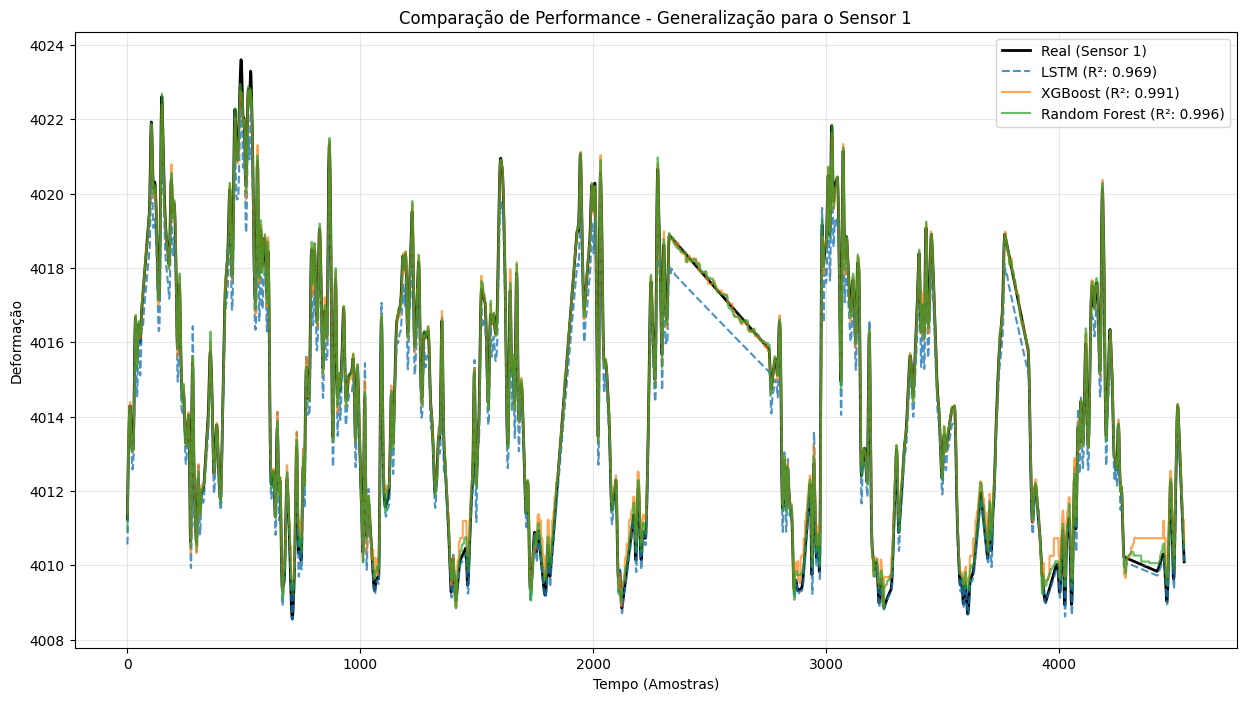

In [ ]:
# 1. Garantir que as matrizes 2D para os modelos clássicos tenham o mesmo tamanho do alvo
X_test_alvo_2d = X_test_alvo.reshape(X_test_alvo.shape[0], X_test_alvo.shape[1])

# 2. Gerar as predições novamente (usando os modelos que já estão na memória)
pred_lstm_scaled = model_lstm.predict(X_test_alvo)
pred_xgb_scaled = model_xgb.predict(X_test_alvo_2d)
pred_rf_scaled = model_rf.predict(X_test_alvo_2d)

# 3. Desescalonar (Voltar para a unidade real de deformação)
pred_lstm = scaler_alvo.inverse_transform(pred_lstm_scaled)
pred_xgb = scaler_alvo.inverse_transform(pred_xgb_scaled.reshape(-1, 1))
pred_rf = scaler_alvo.inverse_transform(pred_rf_scaled.reshape(-1, 1))
y_test_real = scaler_alvo.inverse_transform(y_test_alvo.reshape(-1, 1))

# 4. Mostrar Métricas
print("\n" + "="*50)
print(f"MÉTRICAS ATUALIZADAS - SENSOR {sensor_alvo}")
print("="*50)
r2_lstm = mostrar_metricas(y_test_real, pred_lstm, "LSTM")
r2_xgb  = mostrar_metricas(y_test_real, pred_xgb, "XGBoost")
r2_rf   = mostrar_metricas(y_test_real, pred_rf, "Random Forest")

# 5. Plotagem Comparativa
plt.figure(figsize=(15, 8))
plt.plot(y_test_real, label='Real (Sensor 1)', color='black', linewidth=2, zorder=1)
plt.plot(pred_lstm, label=f'LSTM (R²: {r2_lstm:.3f})', alpha=0.8, linestyle='--')
plt.plot(pred_xgb, label=f'XGBoost (R²: {r2_xgb:.3f})', alpha=0.7)
plt.plot(pred_rf, label=f'Random Forest (R²: {r2_rf:.3f})', alpha=0.7)

plt.title(f"Comparação de Performance - Generalização para o Sensor {sensor_alvo}")
plt.xlabel("Tempo (Amostras)")
plt.ylabel("Deformação")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()